# Cómo llegué hasta aquí

En este cuaderno cuento cómo avanzó el proyecto: por dónde empecé, qué intenté, qué tuve que dejar y
por qué, y en qué punto estoy. Cada etapa cierra con una prueba hecha con los datos del proyecto.

La pregunta es si la cantidad de triages del SES Hospital Universitario de Caldas va a subir en un
periodo próximo, con qué probabilidad y por qué. Lo importante es el por qué. Decir que los lunes
llega más gente es repetir el histórico, y eso es una proyección. Lo que busco es poder decir qué
factores van a hacer que suba, y eso es una predicción. El cuaderno importa porque explica por qué
el análisis quedó planteado como está: cada decisión de método responde a algo que probé antes y
no funcionó, o que funcionó solo a medias.

El camino tuvo cuatro etapas:

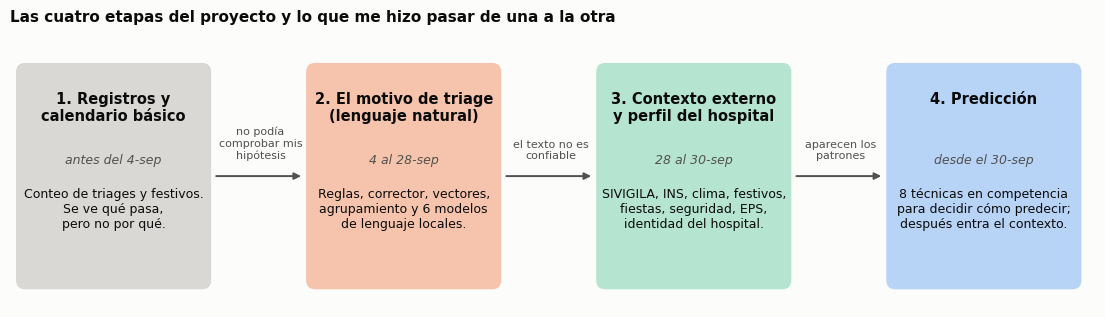

In [1]:
import sys, pathlib, warnings, json
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, display

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
GRIS_CLARO = "#d9d8d4"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
pd.set_option("display.max_colwidth", 90)
pct = lambda x: (np.exp(x) - 1) * 100

FIN = "2026-09-20"
dias = pd.date_range("2020-01-01", FIN)
tri = (pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
         .set_index("dia")["triages"].reindex(dias).astype(float))
tri["2024-03-19":"2024-03-21"] = np.nan                       # caida del registro, no cero pacientes

etapas = [
    ("1. Registros y\ncalendario básico", "antes del 4-sep", "Conteo de triages y festivos.\nSe ve qué pasa,\npero no por qué.", GRIS_CLARO),
    ("2. El motivo de triage\n(lenguaje natural)", "4 al 28-sep", "Reglas, corrector, vectores,\nagrupamiento y 6 modelos\nde lenguaje locales.", "#f6c4ad"),
    ("3. Contexto externo\ny perfil del hospital", "28 al 30-sep", "SIVIGILA, INS, clima, festivos,\nfiestas, seguridad, EPS,\nidentidad del hospital.", "#b5e4d1"),
    ("4. Predicción", "desde el 30-sep", "8 técnicas en competencia\npara decidir cómo predecir;\ndespués entra el contexto.", "#b7d3f6"),
]
gatillos = ["no podía\ncomprobar mis\nhipótesis", "el texto no es\nconfiable", "aparecen los\npatrones"]
fig, ax = plt.subplots(figsize=(14, 3.6)); ax.set_xlim(0, 14.4); ax.set_ylim(0, 3.6); ax.axis("off")
w, sep = 2.55, 1.3
for i, (tit, fecha, cuerpo, col) in enumerate(etapas):
    x = i * (w + sep) + .1
    ax.add_patch(FancyBboxPatch((x, .25), w, 2.9, boxstyle="round,pad=0.02,rounding_size=0.12", fc=col, ec="none"))
    ax.text(x + w / 2, 2.8, tit, ha="center", va="top", fontsize=10.5, weight="bold", color=TINTA)
    ax.text(x + w / 2, 2.0, fecha, ha="center", va="top", fontsize=9, color=TINTA2, style="italic")
    ax.text(x + w / 2, 1.55, cuerpo, ha="center", va="top", fontsize=9, color=TINTA)
    if i < 3:
        xa = x + w + .05
        ax.annotate("", xy=(xa + sep - .1, 1.7), xytext=(xa, 1.7), arrowprops=dict(arrowstyle="-|>", color=TINTA2, lw=1.4))
        ax.text(xa + (sep - .05) / 2, 1.9, gatillos[i], ha="center", va="bottom", fontsize=8, color=TINTA2)
ax.set_title("Las cuatro etapas del proyecto y lo que me hizo pasar de una a la otra", loc="left")
plt.show()

---
# Etapa 1. Los registros y un calendario básico

Empecé con lo que tenía a la mano: el número de triages por día y unos calendarios que armé yo
mismo con festivos, eventos de Manizales, desastres y alertas de salud.

In [2]:
cal0 = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv")
vig0 = pd.read_csv(RAIZ / "calendarios/vigilancia_salud_manizales_caldas.csv")
ev0 = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
des0 = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")
fijas = (vig0.estado == "ventana_estacional").mean() * 100
tabla1 = pd.DataFrame([
    ("Triages por día", f"{tri.notna().sum():,} días", "cuántos llegaron", "no dice por qué llegaron"),
    ("Calendario de Colombia", f"{len(cal0):,} días", "festivos, puentes, quincena, vacaciones", "solo dice qué día es"),
    ("Alertas de salud (a mano)", f"{len(vig0)} filas", "temporadas de gripa, dengue, etc.",
     f"el {fijas:.0f} % son las mismas fechas todos los años; solo {(vig0.ambito_territorial == 'manizales').sum()} son de Manizales"),
    ("Eventos de Manizales (a mano)", f"{len(ev0)} filas", "Feria, conciertos, partidos", "casi todos se repiten igual cada año"),
    ("Desastres (a mano)", f"{len(des0)} filas", "deslizamientos, emergencias", "muy pocos para medir algo"),
], columns=["Lo que tenía", "Tamaño", "Qué traía", "El problema"])
display(tabla1.set_index("Lo que tenía"))

,Tamaño,Qué traía,El problema
Lo que tenía,,,
Triages por día,"2,452 días",cuántos llegaron,no dice por qué llegaron
Calendario de Colombia,"2,557 días","festivos, puentes, quincena, vacaciones",solo dice qué día es
Alertas de salud (a mano),321 filas,"temporadas de gripa, dengue, etc.",el 67 % son las mismas fechas todos los años; solo 40 son de Manizales
Eventos de Manizales (a mano),99 filas,"Feria, conciertos, partidos",casi todos se repiten igual cada año
Desastres (a mano),17 filas,"deslizamientos, emergencias",muy pocos para medir algo


Con esto podía ver la forma de la serie, pero no podía comprobar nada. Yo quería saber, por ejemplo,
si una temporada de frío hace que la gente se enferme de gripa y llegue al triage, aunque sea por la
incapacidad del día. Para eso no basta con saber cuántos llegaron: hay que saber por qué llegaron.
Las alertas de salud que había recogido eran casi todas ventanas con las mismas fechas cada año, o
sea, otro calendario. En una medición temprana sobre 615 días, el calendario ya explicaba el 67,8 %
de la varianza del logaritmo del conteo diario, y lo que sobraba conservaba una autocorrelación de
+0,42 a un día: había estructura sin explicar, pero ninguna de las fuentes que tenía podía nombrarla.

En la práctica, lo único que podía afirmar con estos datos era algo así:

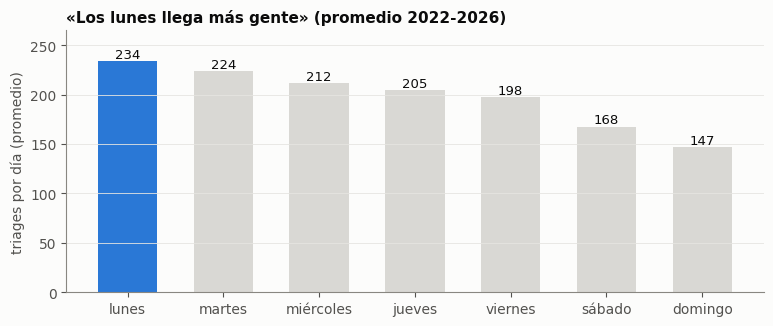

In [3]:
sem = tri["2022-03-01":].groupby(tri["2022-03-01":].index.dayofweek).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(7), sem.values, color=[AZUL if i == 0 else GRIS_CLARO for i in range(7)], width=.62)
for i, v in enumerate(sem.values): ax.text(i, v + 3, f"{v:.0f}", ha="center", fontsize=9.5, color=TINTA)
ax.set_xticks(range(7), ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
ax.set_ylabel("triages por día (promedio)"); ax.grid(axis="x", visible=False); ax.set_ylim(0, 265)
ax.set_title("«Los lunes llega más gente» (promedio 2022-2026)", loc="left")
plt.show()

La figura muestra el promedio de triages por día de la semana desde marzo de 2022. Es cierto que los
lunes llega más gente, pero es justo la proyección que no quiero: no todos los lunes suben igual, y
con estos datos no había forma de saber por qué unos sí y otros no. Esta etapa no permite probar
ninguna hipótesis, porque todo lo que contiene es una repetición del calendario. Por eso pensé que
necesitaba el motivo de consulta.

---
# Etapa 2. El motivo de triage

Cada triage tiene un texto que escribe enfermería al recibir al paciente: el motivo de consulta.
Mi idea era sacar de ahí el tipo de consulta (respiratoria, trauma, dolor…) y cruzarlo con el
clima, las fiestas y lo demás. Si el frío trae gripa, debería verse en las consultas
respiratorias aunque en el total se pierda.

El primer problema fue que ese texto solo existe desde 2025. De los 433.258 triages hasta
septiembre de 2026, solo 94.952 (el 22 %) lo tienen. El segundo problema, y el más grave, fue cómo
está escrito.

## Cómo se ve el texto

Estos ejemplos salen del banco de pruebas que armé con los casos más difíciles. Son frases cortas
que no identifican a nadie.

**Frases que hay que entender, no solo leer:**

| Lo que dice la nota | Lo que quiere decir | Lo que entendió la máquina |
|---|---|---|
| NO ME BAJA EL AZÚCAR | tiene el azúcar alta | todos los modelos dijeron «hipoglucemia», que es lo contrario |
| OÍDOS TAPADOS | sensación de oído tapado | el modelo más grande dijo «otorrea» (salida de líquido del oído) |
| tengo la mano entumida | la mano adormecida | el corrector ortográfico cambió «entumida» por «entubada» |

**Lo que el modelo inventaba (alucinaciones):**

| Lo que dice la nota | Lo que devolvió el modelo | Qué inventó |
|---|---|---|
| ME INDICAN CONSULTAR POR URGENCIAS | dolor abdominal intenso y persistente desde hace 24 horas | la queja entera (la nota es un trámite) |
| ME CAI | posible fractura de brazo izquierdo | el brazo, el lado y la fractura |
| ME CAI Y ME DUELE EL BRAZO | trauma en brazo derecho | el lado |
| CREO QUE SE ME REACTIVÓ LA MIASTENIA | miastenia grave en gestante | un embarazo |
| TIENE FIEBRE Y TOS HACE 2 DÍAS | sin motivo clínico | descartó a un paciente con síntomas |

Y esto no son casos sueltos. Medido sobre las 95.424 notas:

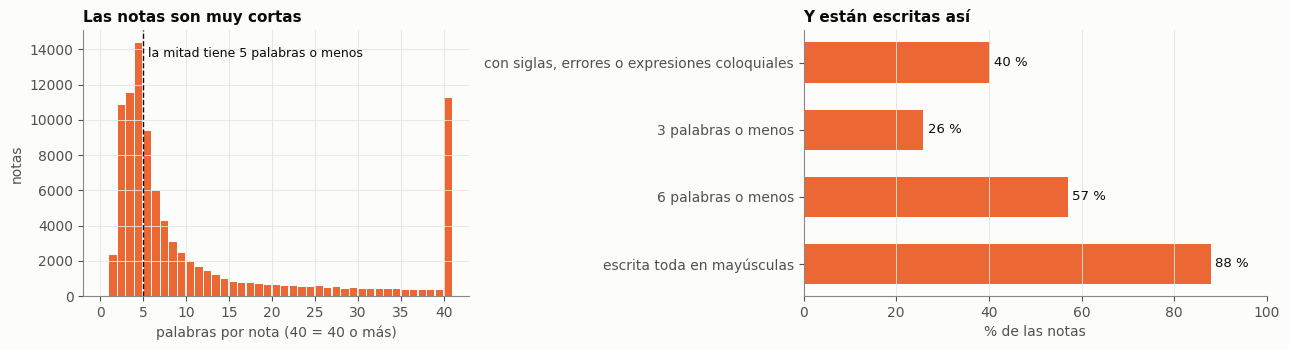

In [4]:
nt = pd.read_csv(RAIZ / "NLP/salidas/tabla/notas_triage.csv.gz", usecols=["nota"])
rec = RAIZ / "NLP/recursos"
s = json.load(open(rec / "siglas.json", encoding="utf-8")); c = json.load(open(rec / "coloquialismos.json", encoding="utf-8"))
no_sig = {"correcciones_directas", "no_restaurar_mayuscula", "patrones_protegidos", *s["_grupos_protegidos"]}
siglas = {k.lower() for g, v in s.items() if not g.startswith("_") and g not in no_sig and isinstance(v, dict) for k in v}
erratas = {k.lower() for k in s.get("correcciones_directas", {})}
coloq = {k.lower() for g, v in c.items() if isinstance(v, dict) for k in v}
texto = nt.nota.fillna(""); bajo = texto.str.lower()
tok = bajo.str.findall(r"[a-záéíóúñü]+"); n_pal = tok.str.len()
raro = tok.apply(lambda w: any(x in siglas or x in erratas for x in w)) | bajo.apply(lambda t: any(e in t for e in coloq))
rasgos = pd.Series({
    "escrita toda en mayúsculas": texto.str.match(r"^[^a-z]*$").mean(),
    "6 palabras o menos": (n_pal <= 6).mean(),
    "3 palabras o menos": (n_pal <= 3).mean(),
    "con siglas, errores o expresiones coloquiales": raro.mean(),
}) * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
a1.hist(n_pal.clip(upper=40), bins=np.arange(0, 42, 1), color=NARANJA, rwidth=.85)
a1.axvline(n_pal.median(), color=TINTA, lw=1, ls="--")
a1.text(n_pal.median() + .6, a1.get_ylim()[1] * .9, f"la mitad tiene {n_pal.median():.0f} palabras o menos", fontsize=9, color=TINTA)
a1.set_xlabel("palabras por nota (40 = 40 o más)"); a1.set_ylabel("notas"); a1.set_title("Las notas son muy cortas", loc="left")
a2.barh(range(len(rasgos)), rasgos.values, color=NARANJA, height=.6); a2.set_yticks(range(len(rasgos)), rasgos.index)
for i, v in enumerate(rasgos.values): a2.text(v + 1, i, f"{v:.0f} %", va="center", fontsize=9.5, color=TINTA)
a2.set_xlim(0, 100); a2.set_xlabel("% de las notas"); a2.grid(axis="y", visible=False)
a2.set_title("Y están escritas así", loc="left")
plt.tight_layout(); plt.show()

La figura de la izquierda muestra que la mitad de las notas tiene 5 palabras o menos; el 57,0 % tiene
6 o menos y el 25,9 %, 3 o menos. A la derecha se ve que el 87,9 % está escrita toda en mayúsculas y
que el 40,2 % trae al menos una sigla, una errata o una expresión coloquial de las que recogí en mis
diccionarios. Como esos diccionarios no están completos, el 40 % es un mínimo.

## Lo que intenté para limpiarlo

| Fecha | Qué hice | Qué pasó |
|---|---|---|
| 4 al 10 de sep | Un proceso de reglas en seis pasos: limpieza, corrección ortográfica, normalización y extracción de conceptos | El corrector va palabra por palabra, no entiende el contexto, y dañaba justo las palabras clínicas |
| 9 al 21 de sep | Un modelo de lenguaje local (qwen) con cuatro diccionarios que hice a mano: siglas del hospital, expresiones de Caldas, lugares y términos clínicos | Entiende mejor la frase, pero inventa cosas y descarta pacientes, y no siempre igual |
| 10 al 22 de sep | Convertir cada nota en un vector y agrupar las notas parecidas | Los grupos salieron por forma de escribir, no por tipo de consulta (abajo) |
| 23 y 24 de sep | Filtros automáticos que borran lo inventado y una segunda revisión para los descartes | Ayudan, pero a veces borran información real cuando la nota tiene un error de escritura |
| 24 y 25 de sep | Una competencia entre 6 modelos (Llama, Gemma, Qwen, Tulu…) con una meta fijada antes de empezar | Ninguno la cumplió. Y sin tarjeta gráfica cada nota tarda de 20 a 120 segundos |

## El agrupamiento

Este es el mapa del agrupamiento que tenía el 15 de septiembre. Cada punto es un texto distinto y
cada color, un grupo de textos parecidos:

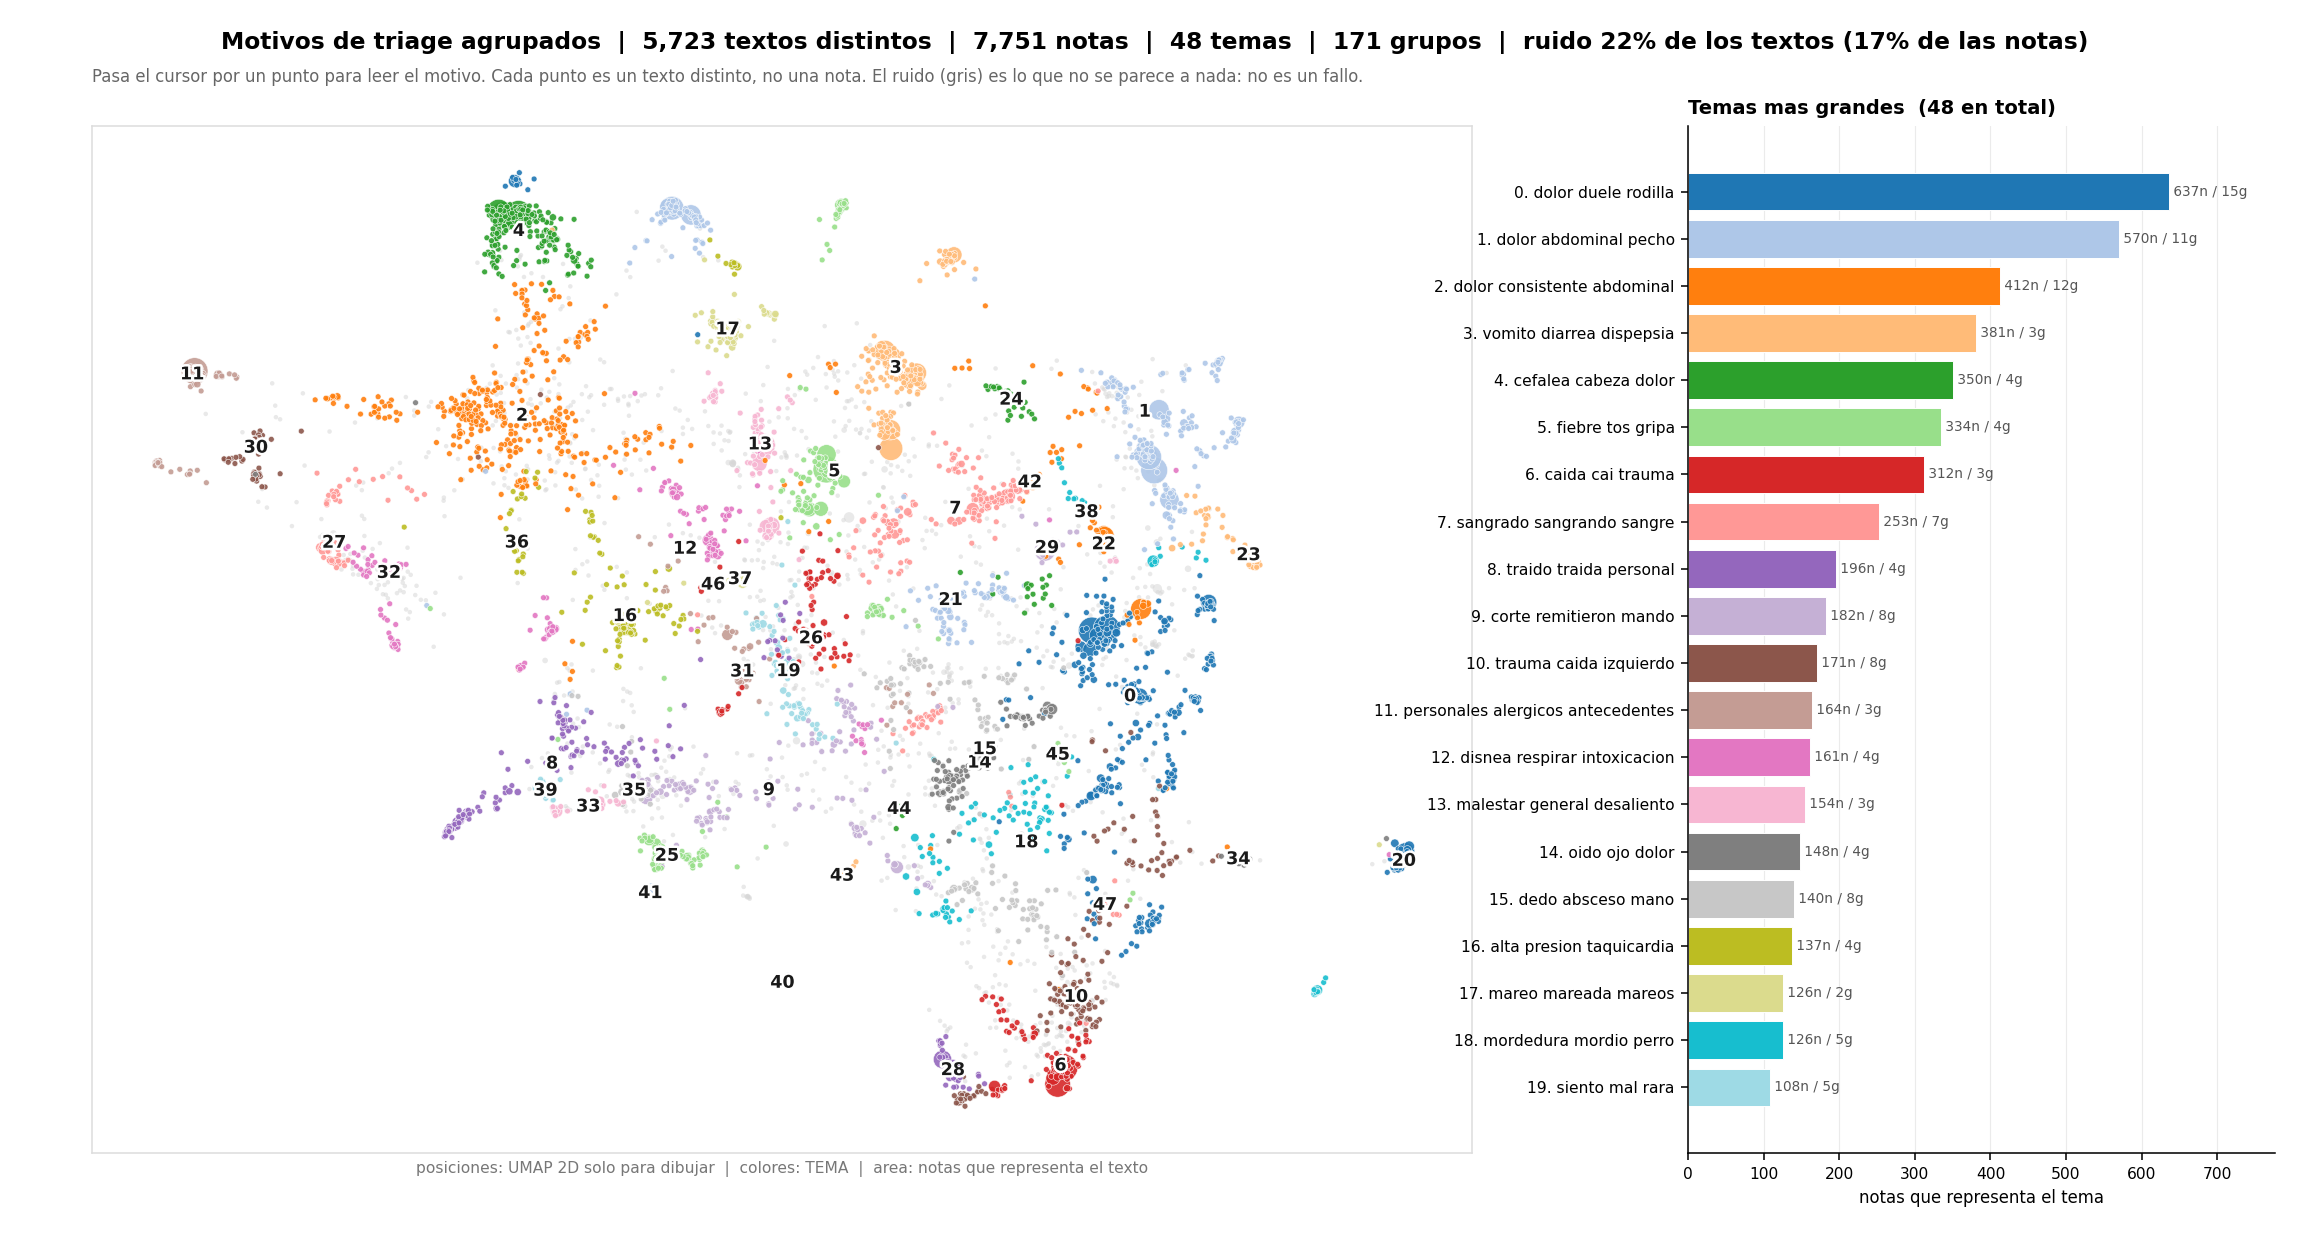

In [5]:
display(Image(filename=str(RAIZ / "clustering/salidas/mapa.png"), width=1100))

A primera vista se ve organizado, pero al revisar los grupos aparecieron los problemas. Los grupos
0, 1, 2 y 4 eran todos «dolor», separados según cómo estaba escrito. El grupo 1 mezclaba dolor de
estómago con dolor de pecho, que no tienen nada que ver. Y algunos grupos juntaban los textos largos,
sin importar de qué hablaban:

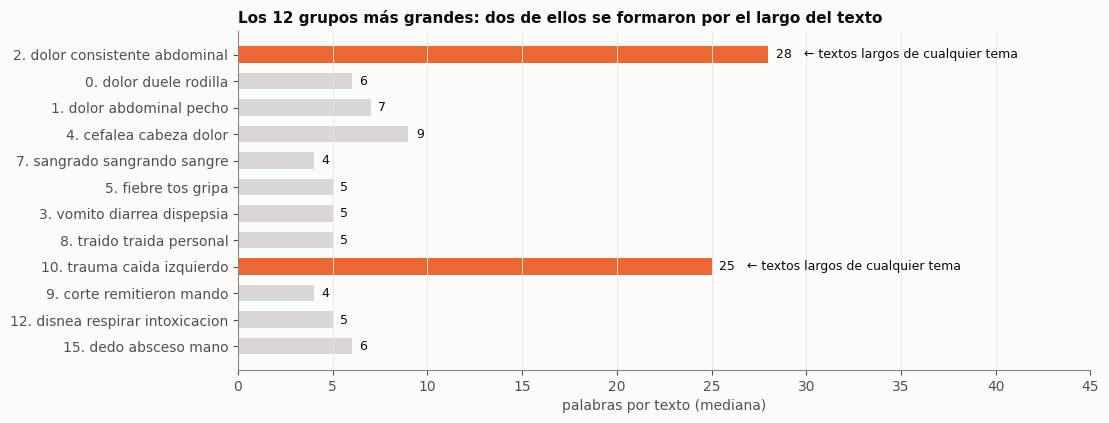

textos que no cayeron en ningún grupo: 22 %


In [6]:
proy = pd.read_parquet(RAIZ / "clustering/salidas/proyeccion.parquet")
temas = pd.read_csv(RAIZ / "clustering/salidas/temas.csv").set_index("tema")
proy["palabras"] = proy.texto.str.split().str.len()
g = proy[proy.tema >= 0].groupby("tema").agg(textos=("fila", "size"), palabras=("palabras", "median"))
g = g.sort_values("textos", ascending=False).head(12)
g["nombre"] = [f"{t}. {temas.loc[t, 'nombre']}" for t in g.index]
largo = g.palabras >= 20
fig, ax = plt.subplots(figsize=(11, 4.4)); y = np.arange(len(g))[::-1]
ax.barh(y, g.palabras, color=[NARANJA if l else GRIS_CLARO for l in largo], height=.62)
for yi, (v, l) in zip(y, zip(g.palabras, largo)):
    ax.text(v + .4, yi, f"{v:.0f}" + ("   ← textos largos de cualquier tema" if l else ""), va="center", fontsize=9, color=TINTA)
ax.set_yticks(y, g.nombre); ax.set_xlabel("palabras por texto (mediana)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 45)
ax.set_title("Los 12 grupos más grandes: dos de ellos se formaron por el largo del texto", loc="left")
plt.show()
print(f"textos que no cayeron en ningún grupo: {(proy.tema < 0).mean() * 100:.0f} %")

La figura ordena por tamaño los 12 grupos más grandes y muestra la mediana de palabras de sus
textos. Los grupos 2 y 10 tienen textos de 25 a 28 palabras, cuando los demás tienen entre 4 y 9: el
algoritmo los juntó por el largo y no por lo que decían. Además, el 22 % de los textos no cayó en
ningún grupo. Por eso volví a limpiar el texto antes de agrupar, pero nunca quedó bien: cada
limpieza arreglaba unas notas y dañaba otras.

## La prueba final

Cuando ya tenía la mejor versión, la probé con 56 notas nuevas que el modelo nunca había visto:

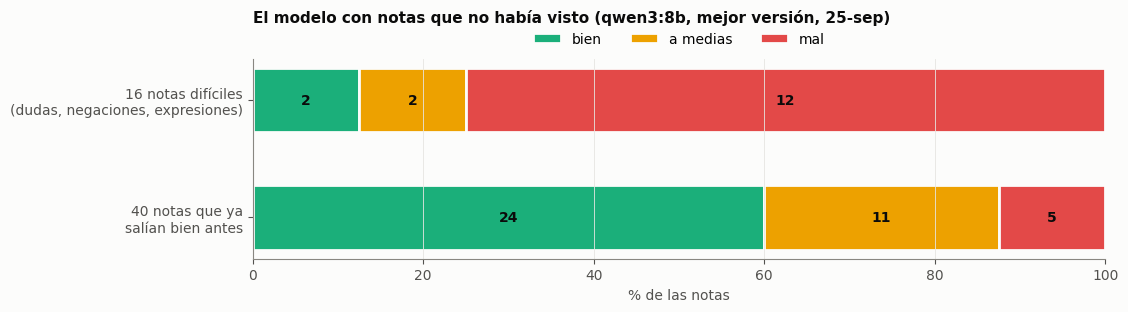

In [4]:
val = pd.DataFrame({"bien": [2, 24], "a medias": [2, 11], "mal": [12, 5]},
                   index=["16 notas difíciles\n(dudas, negaciones, expresiones)", "40 notas que ya\nsalían bien antes"])
fig, ax = plt.subplots(figsize=(11, 2.6)); izq = np.zeros(len(val))
for col, color in [("bien", AQUA), ("a medias", AMARILLO), ("mal", ROJO)]:
    v = val[col].values / val.sum(axis=1).values * 100
    ax.barh(range(len(val)), v, left=izq, color=color, height=.55, label=col, edgecolor=SUP, linewidth=2)
    for i, (l, vi, n) in enumerate(zip(izq, v, val[col].values)):
        if vi > 6: ax.text(l + vi / 2, i, f"{n}", ha="center", va="center", fontsize=10, color=TINTA, weight="bold")
    izq += v
ax.set_yticks(range(len(val)), val.index); ax.set_xlim(0, 100); ax.set_xlabel("% de las notas"); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(.5, 1.0))
ax.set_title("El modelo con notas que no había visto (qwen3:8b, mejor versión, 25-sep)", loc="left", pad=26)
plt.show()

De las 16 notas difíciles, que son las que importan, solo 2 quedaron bien. Y de las 40 que ya
resolvía, dañó 5 al tratar de mejorarlas.

## Por qué dejé el motivo

Después de todo esto, y hablándolo con mi superior, llegué a una conclusión: el texto es demasiado
natural, inexacto o irrelevante, y gran parte de la base está así. Ni las reglas ni los modelos lo
pudieron interpretar, y aunque lo hubiera logrado, seguirían siendo datos poco confiables. Lo que
anota enfermería puede ser un trámite, lo que el paciente cree que tiene, o una interpretación de
quien lo recibe. Un pronóstico armado encima de eso estaría basado en invenciones o inexactitudes.

Por eso nunca hice predicciones con el motivo: la decisión salió de los resultados de la limpieza y
no de un pronóstico fallido. Además, el motivo de mañana solo se conoce cuando el paciente ya llegó,
así que tampoco podía usarse para anticipar nada.

Dejar el texto no obligó a dejar la idea. Más adelante, al medir sin el motivo y solo por grupos de
edad, el mecanismo respiratorio apareció igual. Entre 2022 y 2026, el aporte de 19 variables
externas al residuo semanal quedó por encima del azar en los menores de 15 años (R² incremental de
0,260, con un límite del azar de 0,197) y por debajo en el total (0,112, con un límite de 0,167). En
los niños, cada desviación típica más de temperatura se asoció con un 10 % menos de triages a uno y
dos semanas de rezago (−9,9 % y −10,8 %), es decir, el frío trae más niños, y la humedad con un +6 a
+7 %. La edad, que no identifica a nadie cuando se agrega, hizo el trabajo que yo esperaba
del texto.

---
# Etapa 3. El contexto externo y la identidad del hospital

Dejé el texto y me fui a buscar el por qué afuera del hospital, en fuentes oficiales con historia
de varios años. Y adentro, entendiendo qué tipo de hospital es el SES y quién llega.

| Qué | De dónde | Desde |
|---|---|---|
| Enfermedades de la ciudad por semana: IRA, EDA y 14 eventos más | SIVIGILA del Instituto Nacional de Salud, y su tablero de Power BI para 2026 | 2015 |
| Clima diario: temperatura, lluvia, humedad, viento, radiación | Estaciones del IDEAM y Open-Meteo, revisadas una por una | 2020 |
| Calendario: festivos, puentes, quincena, vacaciones, calendario escolar | Calendario oficial de Colombia y Alcaldía de Manizales | 2020 |
| Feria de Manizales y fiestas de los pueblos de Caldas | Alcaldías y prensa, con fuente | 2020 |
| Riñas, lesiones, accidentes de tránsito, violencia intrafamiliar | Ministerio de Defensa | 2020 |
| Terremoto, emergencias | UNGRD | 2020 |
| El Niño y La Niña | NOAA | 2020 |
| Asegurador de cada triage | Base del hospital (solo conteos) | 2020 |
| Perfil del hospital: a quién ingresa, a quién remite, qué diagnostica | Base del hospital (solo conteos) | 2020 |

Con estos datos sí pude poner a prueba mis hipótesis. Presento tres, y cada una trae su lectura y su
matiz.

## Hipótesis 1. En la Feria de Manizales llegan más accidentados de tránsito

Mi idea era que en las fiestas aumentan los triages por los accidentes: hay más gente, trago y
carros, y son tantos que muchos terminan llegando al SES. Para probarlo comparo los días de Feria
con lo que se esperaría para esos mismos días según el calendario. También comparo con otros
regresos de vacaciones, para que no sea solo «la gente volvió de viaje». Los accidentados de
tránsito se reconocen porque los cubre el SOAT. Para ver si el efecto aparece o se diluye, repito la
misma medición sobre el total y sobre los pacientes particulares.

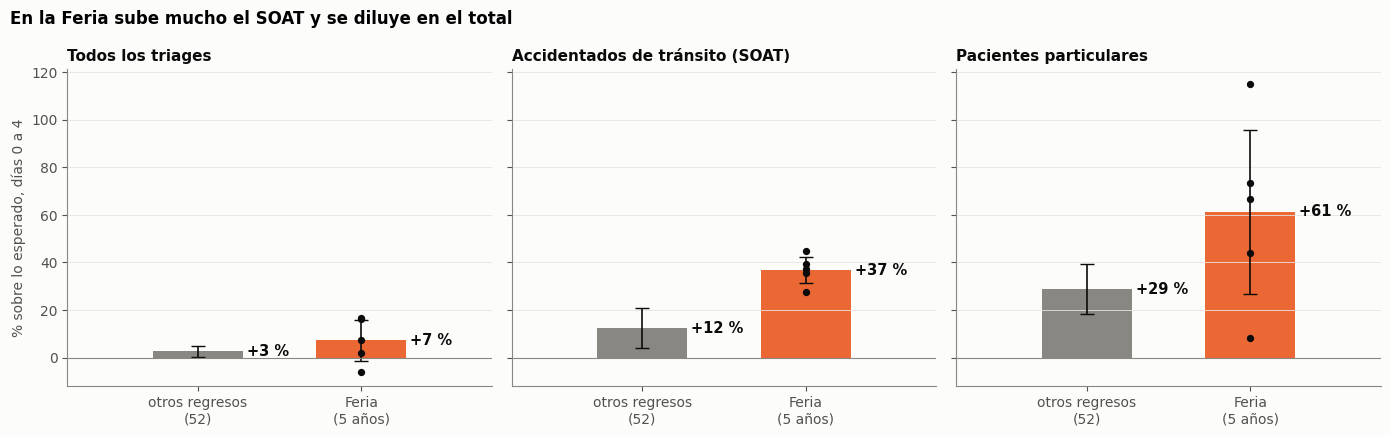

Ferias: ['2020-01-04', '2023-01-02', '2024-01-05', '2025-01-04', '2026-01-03']
Todos los triages                  otros regresos de vacaciones   primeros 5 días: +2.7 % (± 2.3)
Todos los triages                  Feria                          primeros 5 días: +7.3 % (± 8.5)
Accidentados de tránsito (SOAT)    otros regresos de vacaciones   primeros 5 días: +12.5 % (± 8.5)
Accidentados de tránsito (SOAT)    Feria                          primeros 5 días: +36.9 % (± 5.5)
Pacientes particulares             otros regresos de vacaciones   primeros 5 días: +28.9 % (± 10.4)
Pacientes particulares             Feria                          primeros 5 días: +61.3 % (± 34.4)
SOAT en cada Feria: ['+37 %', '+39 %', '+45 %', '+28 %', '+35 %']
Particulares en cada Feria: ['+115 %', '+73 %', '+8 %', '+44 %', '+66 %']
SOAT + particulares: 5.3 % de todos los triages


In [5]:
from extraccion.entidades import clasificar
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio", "es_regreso_colegio"]
COVID = ("2020-03-15", "2022-02-28")
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
         [CAL + ["dia_semana", "es_no_laboral"]].apply(pd.to_numeric, errors="coerce").fillna(0).reindex(dias))
ent = clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
grp = ent.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0)
S = pd.DataFrame({"total": tri, "soat": grp["soat_aseguradora"].where(tri.notna()), "particular": grp["particular"].where(tri.notna())})

# lo esperado: dia de la semana + fechas especiales + nivel de cada anio, ajustado fuera de la COVID (como el cuaderno 07)
Z = pd.concat([pd.get_dummies(cal.dia_semana.astype(int), prefix="d", drop_first=True).astype(float), cal[CAL],
               pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)], axis=1)
Z.insert(0, "c", 1.0)
fuera_covid = ~dias.to_series().between(*COVID).values
def sobre_lo_esperado(y):
    ly = np.log(y + .5); ok = fuera_covid & y.notna().values
    b, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
    return (ly - Z.values @ b).where(y.notna())
R = pd.DataFrame({c: sobre_lo_esperado(S[c]) for c in S})

ev = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
ok_ev = ev.estado.isin(["realizado", "hibrido"]) & ev.fecha_inicio.notna()
ferias = pd.to_datetime(ev[ok_ev & ev.nombre_evento.eq("Feria de Manizales")].fecha_inicio)
ferias = [f for f in ferias if not pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1])]
bloque = cal.es_no_laboral.eq(1)
largo_ = bloque.groupby((~bloque).cumsum()).transform("sum").where(bloque, 0)
regreso = (~bloque) & bloque.shift(1, fill_value=False) & largo_.shift(1).fillna(0).ge(3)
regresos = [d for d in regreso[regreso].index if d.month not in (12, 1)
            and not pd.Timestamp(COVID[0]) <= d <= pd.Timestamp(COVID[1]) and d <= pd.Timestamp(FIN) - pd.Timedelta(days=14)]

def curva(serie, fechas, k=range(-7, 15)):
    return pd.DataFrame({f: serie.reindex([f + pd.Timedelta(days=i) for i in k]).values for f in fechas}, index=list(k))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
res = {}
paneles = [("total", "Todos los triages"), ("soat", "Accidentados de tránsito (SOAT)"), ("particular", "Pacientes particulares")]
for ax, (c, tit) in zip(axes, paneles):
    for j, (fechas, col, nom) in enumerate([(regresos, MUDO, "otros regresos de vacaciones"), (ferias, NARANJA, "Feria")]):
        v = pct(curva(R[c], fechas)).loc[0:4].mean()                 # promedio de los dias 0 a 4 de cada episodio
        m, e = v.mean(), 1.96 * v.std() / np.sqrt(v.notna().sum()); res[(tit, nom)] = (m, e, v)
        ax.bar(j, m, color=col, width=.55); ax.errorbar(j, m, yerr=e, color=TINTA, capsize=5, lw=1.2)
        ax.text(j + .3, m, f"{m:+.0f} %", va="center", fontsize=10.5, weight="bold", color=TINTA)
        if fechas is ferias:
            ax.scatter(np.full(len(v), j), v.values, s=18, color=TINTA, zorder=3)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks([0, 1], [f"otros regresos\n({len(regresos)})", f"Feria\n({len(ferias)} años)"])
    ax.set_xlim(-.8, 1.8); ax.set_title(tit, loc="left"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% sobre lo esperado, días 0 a 4")
fig.suptitle("En la Feria sube mucho el SOAT y se diluye en el total", x=.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
print("Ferias:", [f"{f:%Y-%m-%d}" for f in ferias])
for (t, n), (m, e, v) in res.items(): print(f"{t:34s} {n:30s} primeros 5 días: {m:+.1f} % (± {e:.1f})")
print("SOAT en cada Feria:", [f"{x:+.0f} %" for x in res[("Accidentados de tránsito (SOAT)", "Feria")][2]])
print("Particulares en cada Feria:", [f"{x:+.0f} %" for x in res[("Pacientes particulares", "Feria")][2]])
print(f"SOAT + particulares: {100 * (S.soat + S.particular).sum() / S.total.sum():.1f} % de todos los triages")

La figura mide, para los primeros cinco días de cada Feria, cuánto se aleja el conteo de lo que el
calendario esperaba, y lo compara con 52 regresos de vacaciones que no son Feria. En esos cinco
días, los accidentados de tránsito que llegan al SES suben un 37 % por encima de lo esperado; en
otros regresos suben un 12 %. Es casi el triple, y pasa todos los años: cada una de las cinco Ferias
queda entre +28 % y +45 % (2020, 2023, 2024, 2025 y 2026; las de 2021 y 2022 cayeron en la
COVID). Los pacientes particulares también suben, un 61 %, pero con mucha más dispersión (de +8 % a
+115 % según el año), y los otros regresos ya los llevan a +29 %, así que no los uso como prueba.

El hallazgo que más pesa para el proyecto es el primer panel: sobre **todos los triages** la Feria
sube un 7 %, con un margen de ±8,5, casi indistinguible de un regreso de vacaciones (+3 %). El efecto
existe, pero ocurre en un grupo pequeño de pacientes: SOAT y particulares juntos son una fracción
chica del volumen (el 5,3 %, según la última línea de la salida), y al sumarlo todo se diluye. Medir esta hipótesis
sobre el total la habría escondido.

Lo que no puedo probar con estos datos es de dónde vienen. El resto del año, los accidentes que
registra la Policía en la ciudad no se mueven igual que los del SES (los accidentados de Manizales
van sobre todo a otras clínicas), y en la Feria la serie de la Policía cambia mucho de un año a
otro, porque solo cuenta lo que se denuncia. Saber si llegan aquí porque las otras clínicas se
llenan requeriría la información de remisiones del CRUE. Con cinco Ferias, además, el número de
episodios es pequeño.

## Hipótesis 2. Cuando la ciudad se enferma de IRA, llegan más niños al SES

Esta es la versión medible de la idea de la gripa. El SIVIGILA cuenta cada semana las consultas
por infección respiratoria aguda (IRA) en las instituciones de Manizales. Si mi hipótesis es
cierta, cuando suben las IRA de los niños en la ciudad, también deberían subir los triages de
niños en el SES.

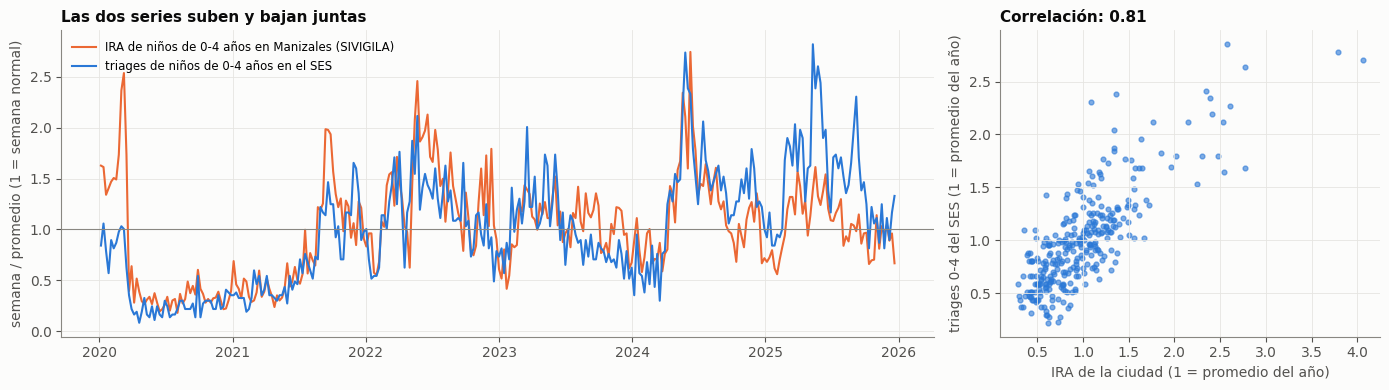

312 semanas (2020-2025). Correlación en conteo: 0.70; comparando cada año contra su promedio: 0.81


In [6]:
viga = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira04 = (viga[(viga.evento == 995) & (viga.ambito == "manizales") & (viga.variable == "consultas_ira_0_4")]
           .set_index("fecha_inicio_semana").valor.sort_index())
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet"); ed["dia"] = pd.to_datetime(ed.dia)
t04 = (ed[ed.banda == "0-4"].groupby("dia").n.sum().reindex(pd.date_range("2020-01-01", "2025-12-31")).fillna(0)
         .resample("W-SUN", label="left", closed="left").sum())            # semana epidemiologica: domingo a sabado
W = pd.DataFrame({"ciudad": ira04, "ses": t04}).dropna().loc["2020-01-01":"2025-12-27"]
Wa = W.groupby(W.index.year).transform(lambda s: s / s.mean())             # cada anio contra su propio promedio
r, r_a = W.ciudad.corr(W.ses), Wa.ciudad.corr(Wa.ses)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.3, 1]})
a1.plot(W.index, W.ciudad / W.ciudad.mean(), color=NARANJA, lw=1.5, label="IRA de niños de 0-4 años en Manizales (SIVIGILA)")
a1.plot(W.index, W.ses / W.ses.mean(), color=AZUL, lw=1.5, label="triages de niños de 0-4 años en el SES")
a1.axhline(1, color=MUDO, lw=.8); a1.set_ylabel("semana / promedio (1 = semana normal)")
a1.legend(loc="upper left", fontsize=8.5); a1.set_title("Las dos series suben y bajan juntas", loc="left")
a2.scatter(Wa.ciudad, Wa.ses, s=12, color=AZUL, alpha=.6)
a2.set_xlabel("IRA de la ciudad (1 = promedio del año)"); a2.set_ylabel("triages 0-4 del SES (1 = promedio del año)")
a2.set_title(f"Correlación: {r_a:.2f}", loc="left")
plt.tight_layout(); plt.show()
print(f"{len(W)} semanas (2020-2025). Correlación en conteo: {r:.2f}; comparando cada año contra su promedio: {r_a:.2f}")

Durante seis años, las semanas en que la ciudad tiene más IRA en niños pequeños son las mismas en
que llegan más niños al SES. La correlación semanal es de 0,70, y de 0,81 si cada año se compara
contra su propio promedio. Es una relación fuerte para dos fuentes que no tienen nada que ver entre
sí (el SES casi no reporta IRA al SIVIGILA, así que no son las mismas consultas contadas dos veces).
La relación no tiene dirección: la correlación es 0,70 sin desfase y 0,69 con una semana de
adelanto, y la medición por edad del cuaderno 13 muestra que las dos series se mueven en la misma
semana, de modo que la ciudad no avisa con semanas de adelanto. La cautela es que ambas series
comparten la estación del año, de modo que la figura muestra que las dos coinciden en la
temporada respiratoria, no que cada ola de la ciudad empuje al hospital.

Para ver por qué esta relación no se nota en el total, medí cuánto sube el mes más alto sobre el más
bajo en cada grupo de edad, entre 2021 y 2025:

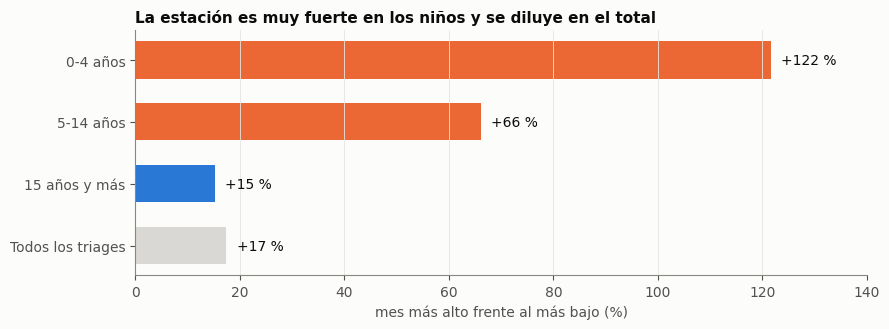

{'0-4 años': 121.6, '5-14 años': 66.1, '15 años y más': 15.2, 'Todos los triages': 17.4}


In [7]:
ed2 = ed.assign(g=ed.banda.map({"0-4": "0-4 años", "5-14": "5-14 años", "15-44": "15 años y más",
                                "45-64": "15 años y más", "65-+": "15 años y más"})).dropna(subset=["g"])
dd = pd.date_range("2021-01-01", "2025-12-31")
B = ed2.groupby(["dia", "g"]).n.sum().unstack().reindex(dd).fillna(0)
B["Todos los triages"] = B.sum(axis=1)
mes = B.groupby(B.index.month).mean()
amp = (mes.max() / mes.min() - 1) * 100
orden_e = ["0-4 años", "5-14 años", "15 años y más", "Todos los triages"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(range(4)[::-1], amp[orden_e].values, color=[NARANJA, NARANJA, AZUL, GRIS_CLARO], height=.6)
for yi, v in zip(range(4)[::-1], amp[orden_e].values): ax.text(v + 2, yi, f"{v:+.0f} %", va="center", fontsize=10, color=TINTA)
ax.set_yticks(range(4)[::-1], orden_e); ax.set_xlim(0, 140); ax.grid(axis="y", visible=False)
ax.set_xlabel("mes más alto frente al más bajo (%)")
ax.set_title("La estación es muy fuerte en los niños y se diluye en el total", loc="left")
plt.tight_layout(); plt.show()
print(amp[orden_e].round(1).to_dict())

En los menores de cinco años el mes más alto supera al más bajo en un 122 %, en los de 5 a 14 en un
66 %, y en los mayores de 15 en un 15 %. Como los niños son una parte del volumen, el total solo
oscila un 17 %. Ese es el mecanismo de dilución que me llevó a mirar por edad y no solo el total.

Esta hipótesis tiene matices que medí después y que conviene dejar a la vista, porque el efecto
depende de cómo se mide:

| Eslabón | Qué medí | Resultado |
|---|---|---|
| Clima → IRA de la ciudad | Barrido de clima completo, 2012-2024, 266 pruebas con corrección de Benjamini-Hochberg | 53 pruebas sobreviven (la cuenta ingenua del 5 % daría unas 13; el azar calibrado del cuaderno 12 da 0,75): un mes lluvioso, nublado y húmedo trae +6 a +7 % de IRA a 1-5 semanas |
| IRA y otras familias de enfermedad → triage total | Seis familias semanales de la ciudad, rezagos de 0 a 4 semanas | 4 de 30 pruebas sobreviven, con efectos de 1 a 3 % |
| Contexto → triage por edad | 65 pruebas por grupo, 2022-2024 | Efecto máximo que sobrevive: 7,7 % en 0-4, 6,9 % en 5-14, 4,6 % en 65+, contra 2,1 % en el total. Valen solo para el descubrimiento: en 2025-2026 las firmas por banda de edad no se confirman (de 32, 8 conservan el signo, 1 se confirma y 4 se invierten, cuaderno 21) |
| Semana más fría que lo normal → niños | Anomalía contra la misma semana del año, rezagos de 0 a 4 semanas | Diferencias entre −3 % y +2 %, sin patrón; una regresión distinta dio +8 a +10 % |

Esto último no lo leo como «el clima no importa». Lo leo como que mi diseño sencillo, de una sola
variable de nivel, no podía ver un efecto que depende de una transición, de un rezago y de un
subgrupo. El resultado depende del método, y por eso dejé de buscar un factor único para el total.

## Hipótesis 3. La caída del volumen tiene una causa externa: la crisis de Nueva EPS

Desde 2025 el triage venía cayendo y no sabía por qué. Al separar por asegurador apareció la
respuesta:

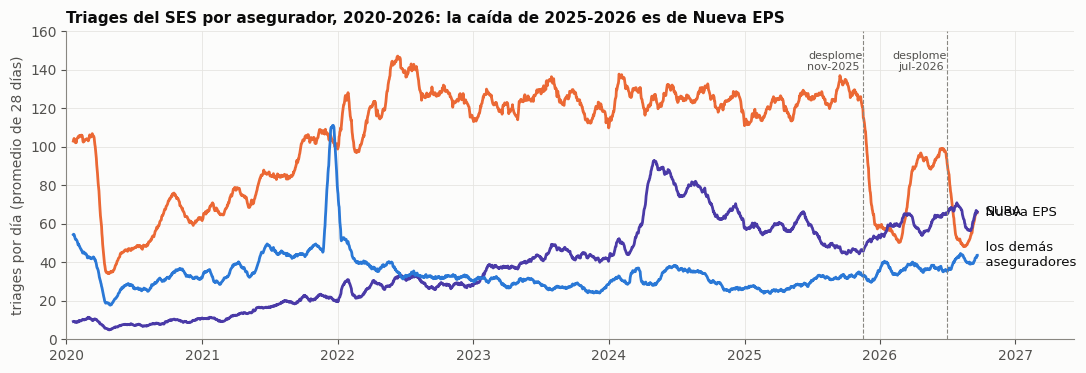

Nueva EPS por día:   {2020: 64.8, 2021: 86.1, 2022: 125.3, 2023: 122.9, 2024: 125.6, 2025: 115.8, 2026: 72.2}
SURA por día:        {2020: 8.6, 2021: 16.8, 2022: 28.5, 2023: 41.1, 2024: 69.6, 2025: 53.9, 2026: 62.0}
Demás aseguradores:  {2020: 32.3, 2021: 46.4, 2022: 35.8, 2023: 28.4, 2024: 31.6, 2025: 29.9, 2026: 38.4}
Total por día:       {2020: 105.7, 2021: 149.3, 2022: 189.6, 2023: 192.4, 2024: 226.9, 2025: 199.6, 2026: 172.6}


In [8]:
grupo = pd.read_csv(RAIZ / "salidas/entidades_clasificadas.csv").set_index("entidad_oid")["grupo"]
e2 = pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet")
e2["quien"] = e2.entidad_oid.map(grupo).map(lambda g: g if g in ("nueva_eps", "sura_eps") else "resto")
d = e2.groupby([pd.to_datetime(e2.dia), "quien"]).n.sum().unstack(fill_value=0).reindex(dias, fill_value=0)
d.loc["2024-03-19":"2024-03-21"] = np.nan
rr = d.rolling(28, min_periods=20).mean()
fig, ax = plt.subplots(figsize=(13, 4))
for col, color, nom in [("nueva_eps", NARANJA, "  Nueva EPS"), ("sura_eps", VIOLETA, "  SURA"), ("resto", AZUL, "  los demás\n  aseguradores")]:
    ax.plot(rr.index, rr[col], color=color, lw=2); ax.text(rr.index[-1], rr[col].iloc[-1], nom, color=TINTA, va="center", fontsize=9.5)
for f, t in [("2025-11-15", "desplome\nnov-2025"), ("2026-07-01", "desplome\njul-2026")]:
    ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls="--"); ax.text(pd.Timestamp(f), 150, t + " ", ha="right", va="top", fontsize=8, color=TINTA2)
ax.set_xlim(rr.index[0], rr.index[-1] + pd.Timedelta(days=260)); ax.set_ylim(0, 160)
ax.set_ylabel("triages por día (promedio de 28 días)")
ax.set_title("Triages del SES por asegurador, 2020-2026: la caída de 2025-2026 es de Nueva EPS", loc="left")
plt.show()
a = d.groupby(d.index.year).mean().round(1)
print("Nueva EPS por día:  ", a["nueva_eps"].to_dict()); print("SURA por día:       ", a["sura_eps"].to_dict()); print("Demás aseguradores: ", a["resto"].to_dict())
print("Total por día:      ", d.sum(axis=1, min_count=1).groupby(d.index.year).mean().round(1).to_dict())

La figura separa el volumen por asegurador con un promedio móvil de 28 días. Nueva EPS, que está
intervenida por el Gobierno y en crisis financiera, es el asegurador más grande del SES. Entre 2025 y
2026 sus triages bajan de 115,8 a 72,2 por día (−38 %), con dos desplomes: noviembre de 2025 y julio
de 2026. El total pasa de 226,9 triages por día en 2024 a 172,6 en 2026. Esto no estaba en ningún
calendario, y por eso el modelo necesita una variable con el estado de la red de salud.

La caída se parece más a una barrera de acceso que a un traslado de pacientes. Con los afiliados de
Manizales publicados por el Ministerio de Salud (julio de 2025 a agosto de 2026), Nueva EPS perdió el
19,5 % de sus afiliados, pero su triage cayó un 60 %, de modo que el uso por afiliado bajó un 50 %.
SURA, en cambio, ganó un 14 % de afiliados y un 14 % de triage, con el mismo uso por afiliado. Los
demás aseguradores compensan poco: el 16 % de lo perdido en noviembre de 2025 y el 11 % en julio de
2026 con una ventana, y el 13 % y el 22 % con otra (cuaderno 01), de modo que la cifra exacta depende
de la ventana; el total cayó un 28 % y un 19 % en esos meses. Las resoluciones de la Superintendencia de
Salud del 14 y el 25 de noviembre de 2025 coinciden con el escalón del 15 de noviembre; las caídas de
marzo y julio de 2026 no tienen resolución cercana y probablemente se deben a decisiones de
contratación que no son públicas.

El matiz medido es que esta explicación vale para 2025 y 2026. El pico de 2024 y su bajada a 2025
no son de Nueva EPS, que casi no se mueve entre 2022 y 2024: sube SURA, de 41,1 a 69,6 triages por
día entre 2023 y 2024, y luego baja a 53,9 en 2025. Esa variación proviene de un solo asegurador y
no puedo atribuirla con estos datos a una causa externa concreta.

Con estas tres hipótesis vi que los datos externos explican cambios del triage, pero que lo hacen
en un grupo, en una fecha o en un asegurador concretos, y no sobre el volumen total promedio. De ahí
salió la forma en que planteé la predicción.

## Otros factores que medí

Antes de pasar a predecir recorrí el resto de los factores con el mismo criterio de buscar su reloj,
su gatillo y su subgrupo:

| Factor | Resultado | Lectura y cautela |
|---|---|---|
| Familias de enfermedad de la ciudad | El clima mueve a las transmisibles: las semanas largas sin lluvia fuerte suben la digestiva +15,7 % y una racha seca baja la respiratoria −9,5 % a 3 semanas | Sobre el total del hospital los efectos son de 1 a 3 %; el cuaderno 17 muestra que el efecto del clima sobre el total no es el de la IRA diluida (correlación de −0,35 entre los efectos sobre una y otro) |
| Regímenes climáticos | El Niño asociado a +3,6 % de triage (p < 0,001); La Niña sube violencias y salud mental de la ciudad, y la salud mental descansa en un solo episodio, la alerta del volcán de 2023 (cuaderno 19) | El Niño es un solo episodio dentro de la ventana del hospital y coincide con el año récord y la entrada de SURA |
| Sismos | Con 40 episodios no mueven ni a la ciudad ni al hospital | Es un resultado negativo con muestra; el terremoto de agosto de 2026 es otro caso: −50 % el día, −26 % la primera semana y −7 % los días 8-21 con el método semanal, y −48,7 % el día 0 y −22,3 % los días 1-7 al comparar el episodio con las 8 semanas previas (cuaderno 20) |
| Estado de la red de aseguradores | Entran al modelo seis variables de red | Describen la red, pero no la anticipan |

Del régimen de El Niño dejé escrita una predicción antes de saber el resultado: entre el 4 de octubre
y el 26 de diciembre de 2026, el triage real debería superar en al menos +2 % de media a la mediana
de la combinación congelada, que no usa esta variable. Si no lo hace, la hipótesis se rechaza. Esa
es la diferencia entre proyectar y predecir que me interesa mantener.

---
# Etapa 4. Las predicciones

Antes de meter todas las variables quise saber qué técnica predice mejor. Por eso, en esta primera
fase, todos los modelos reciben lo mismo: la serie del triage, el calendario y la época del año. Así
lo que comparo es la técnica y no los datos que recibe cada una. Cuando sé cuáles funcionan, les
agrego el contexto externo y mido cuánto mejoran.

**Cómo los pongo a prueba.** Para cada día entre el 1 de enero de 2025 y el 13 de septiembre de
2026, el modelo solo conoce lo que pasó hasta ese día y predice los 7 días posteriores. Después
comparo con lo que de verdad pasó. Esto se llama validación de origen rodante, y evita que el
modelo vea el futuro. Son 622 días de partida y 4.354 predicciones por modelo.

**Qué mido.** El calendario solo ya acierta bastante (se equivoca un 10 % en promedio), así que lo
que me interesa es lo que el calendario no ve: los días en que la demanda se sale de lo normal.
Por eso mido sobre todo cuánto de esas subidas y bajadas anticipa cada modelo.

## Los ocho modelos

| Modelo | Tipo | Cómo funciona |
|---|---|---|
| Ingenuo | base de comparación | Mañana será igual que el mismo día de la semana pasada |
| Control de calendario | base de comparación | Promedio según el día de la semana, festivos, quincena, vacaciones y el nivel del último mes |
| Regresión binomial negativa | estadística clásica | Una regresión hecha para contar cosas (personas por día), que además dice cuánto pesa cada factor |
| LightGBM | aprendizaje automático | Cientos de árboles de decisión pequeños; cada uno corrige los errores del anterior |
| SARIMAX | series de tiempo | Aprende del día anterior y de la misma semana pasada, y se actualiza todos los días con lo último observado |
| Prophet | series de tiempo (Meta) | Separa la serie en tendencia, ciclo semanal, ciclo anual y fechas especiales |
| Chronos-2 | inteligencia artificial preentrenada (Amazon) | Un modelo entrenado con miles de series de todo tipo; predice sin entrenarlo con mis datos |
| Chronos-2 + calendario | inteligencia artificial preentrenada | El mismo, pero diciéndole además qué días son festivos o especiales |

Cada uno predice una distribución y no un solo número: un valor central y un rango. De ahí sale
la probabilidad de que el día suba.

## Así predijo cada uno

Predicción a un día, de junio a septiembre de 2026. La franja azul es el rango donde el modelo
espera que caiga el valor con un 80 % de probabilidad, y los puntos son lo que de verdad pasó.

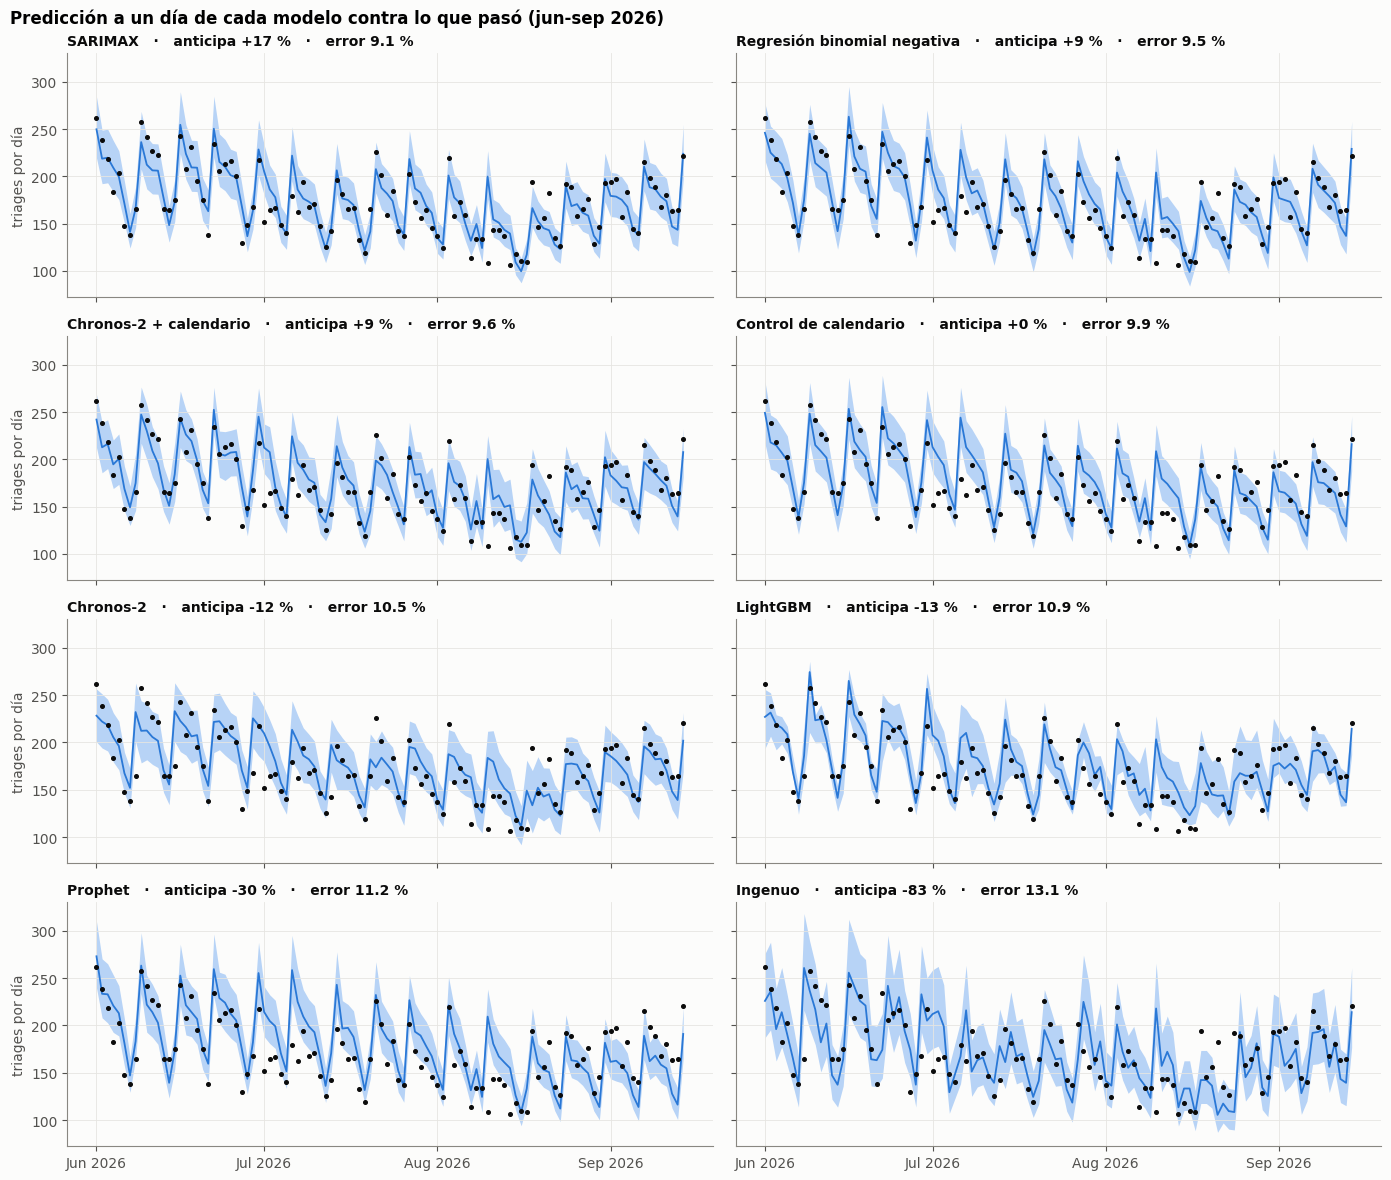

In [9]:
import pronostico as pr
NOMBRES = {"sarimax": "SARIMAX", "glm_binneg": "Regresión binomial negativa", "chronos2_cal": "Chronos-2 + calendario",
           "control": "Control de calendario", "chronos2": "Chronos-2", "lightgbm": "LightGBM",
           "prophet": "Prophet", "ingenuo": "Ingenuo"}
Pr, U = pr.leer(list(NOMBRES))
Pm, T = pr.metricas(Pr, U)
T = T.rename(index=NOMBRES).sort_values("R2 desvio %", ascending=False)
orden = sorted(NOMBRES, key=lambda k: -T.loc[NOMBRES[k], "R2 desvio %"])
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)
for ax, m in zip(axes.flat, orden):
    s_ = Pm[(Pm.modelo == m) & (Pm.h == 1)].set_index("fecha").sort_index()["2026-06-01":]
    ax.fill_between(s_.index, s_.q10, s_.q90, color="#b7d3f6", lw=0)
    ax.plot(s_.index, s_.q50, color=AZUL, lw=1.3)
    ax.plot(s_.index, s_.real, color=TINTA, lw=0, marker="o", ms=2.6)
    t = T.loc[NOMBRES[m]]
    ax.set_title(f"{NOMBRES[m]}   ·   anticipa {t['R2 desvio %']:+.0f} %   ·   error {t['MAPE %']:.1f} %", loc="left", fontsize=10)
import matplotlib.dates as mdates
for ax in axes[:, 0]: ax.set_ylabel("triages por día")
for ax in axes[-1]: ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Predicción a un día de cada modelo contra lo que pasó (jun-sep 2026)", x=.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()

La figura ordena los modelos de mejor a peor. «Anticipa» es la parte de las subidas y bajadas que el
calendario no explica y que el modelo sí vio venir; un valor negativo quiere decir que lo hace peor
que el calendario solo. «Error» es el error promedio de la predicción. La cautela es que son cuatro
meses de 2026, un periodo en el que el nivel de Nueva EPS ya había caído.

días que suben sobre el calendario: 45 %; decir siempre «no sube» acierta el 55 %


,anticipa lo que el calendario no ve (%),mejora en la probabilidad de «sube» (%),acierta si sube o baja (%),cae dentro del rango del 80 % (%),error promedio (%)
modelo,,,,,
SARIMAX,17.1,9.0,62.4,78.0,9.1
Regresión binomial negativa,9.3,4.0,59.3,77.7,9.5
Chronos-2 + calendario,8.6,4.1,61.1,78.5,9.6
Control de calendario,0.0,-0.9,54.8,72.8,9.9
Chronos-2,-11.7,-1.3,59.6,79.0,10.5
LightGBM,-13.0,-9.1,56.1,64.9,10.9
Prophet,-30.2,-22.5,47.6,64.2,11.2
Ingenuo,-83.4,-13.4,55.5,77.1,13.1


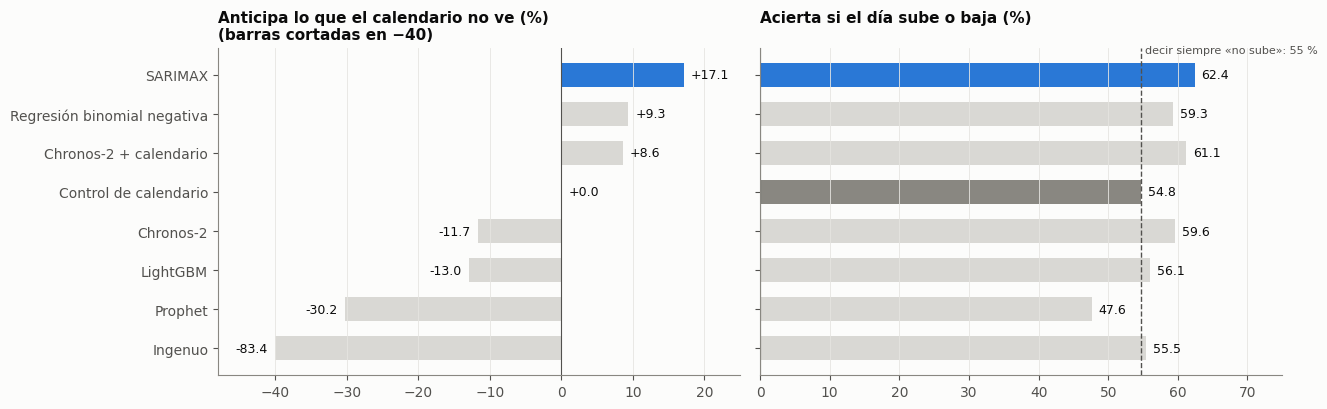

In [10]:
p_sube = Pm[Pm.modelo == "sarimax"].sobre.mean()
base_trivial = 100 * max(p_sube, 1 - p_sube)
print(f"días que suben sobre el calendario: {100 * p_sube:.0f} %; decir siempre «no sube» acierta el {base_trivial:.0f} %")
cols = {"R2 desvio %": "anticipa lo que el calendario no ve (%)", "BSS sube %": "mejora en la probabilidad de «sube» (%)",
        "acierta sube/baja %": "acierta si sube o baja (%)", "cob80 %": "cae dentro del rango del 80 % (%)", "MAPE %": "error promedio (%)"}
display(T[list(cols)].rename(columns=cols).round(1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 4.2), sharey=True)
yy = np.arange(len(T))[::-1]
def barras(ax, col, titulo, piso):
    v = T[col].values
    colores = [AZUL if n == "SARIMAX" else (MUDO if n.startswith("Control") else GRIS_CLARO) for n in T.index]
    ax.barh(yy, np.maximum(v, piso), color=colores, height=.62)
    for yi, vi in zip(yy, v):
        ax.text(max(vi, piso) + (1 if vi >= 0 else -1), yi, f"{vi:+.1f}" if piso < 0 else f"{vi:.1f}",
                va="center", ha="left" if vi >= 0 else "right", fontsize=9, color=TINTA)
    ax.axvline(0, color=TINTA2, lw=.8); ax.set_title(titulo, loc="left"); ax.grid(axis="y", visible=False)
barras(a1, "R2 desvio %", "Anticipa lo que el calendario no ve (%)\n(barras cortadas en −40)", -40)
barras(a2, "acierta sube/baja %", "Acierta si el día sube o baja (%)\n", 0)
a1.set_yticks(yy, T.index); a1.set_xlim(-48, 25); a2.set_xlim(0, 75)
a2.axvline(base_trivial, color=TINTA2, lw=1, ls="--")
a2.text(base_trivial + .5, 7.55, f"decir siempre «no sube»: {base_trivial:.0f} %", fontsize=8, color=TINTA2)
plt.tight_layout(); plt.show()

## Lo que me dicen estas primeras predicciones

- SARIMAX va adelante. Es el que más anticipa de lo que el calendario no explica, y acierta si el
  día sube o baja el 62 % de las veces. Para comparar bien: como solo el 45 % de los días suben,
  decir siempre «no sube» ya acertaría el 55 %, y el calendario solo también da 55 %. SARIMAX le
  saca 7 puntos a eso sin ningún dato externo, y queda dentro del 60-70 % que me puse como meta.
  Su rango del 80 % contiene el valor real el 78 % de las veces, o sea que no se cree más seguro
  de lo que es.
- La regresión y Chronos-2 con calendario también anticipan algo. Los demás lo hacen peor que el
  calendario solo. Los que no tienen el calendario metido de forma explícita salen mal, lo que
  muestra que el calendario es la base sobre la que se construye.
- Esto es solo con la serie del triage. Mide la técnica, no el contexto.

## Cuando entró el contexto

Después probé lo que me importaba, que es meter el contexto externo. Lo hice con una regla fijada
antes de calcular: a cada año de prueba (2023 a 2026) se le entrena solo con lo anterior, y se compara
contra el mismo modelo sin contexto.

**El motor se corrigió primero.** Un árbol no predice valores que no vio, y el nivel de 2024 (227
triages por día) superó todo el entrenamiento. Al cambiar el objetivo de «el conteo» a «el desvío
frente al nivel», la base de 2024 pasó de un acierto del 42 % a uno del 66,3 %. Ese motor corregido
(C0r) quedó con un acierto del 61,9 % y un error del 8,5 % en 2025.

**Meter todo el contexto sobre el total ajustó ruido.** Con unos 2.400 días y 24 variables, el modelo
empeoró justo en los días estables, donde el contexto no debería actuar (−6,8 puntos). Concuerda con
la literatura de urgencias: añadir clima casi nunca mejora el error del total (Wargon et al. 2009, en
una revisión de 9 estudios; Marcilio, Hajat y Gouveia 2013, en São Paulo), y lo que ayuda es el estado del sistema, como las camas o
las epidemias.

**La compuerta repara casi todo el daño.** Cada familia de contexto se enciende solo cuando su
gatillo está activo. Con la compuerta de salud pública, el modelo igualó o mejoró a la base en los
cuatro años y en los siete tipos de día. Mejora de la probabilidad de «sube» (BSS, en puntos; más alto
es mejor), en una selección de tipos de día:

| Tipo de día | Sin contexto | Con compuerta de salud pública |
|---|---|---|
| Ola de salud pública | +5,1 | +8,8 |
| El Niño o La Niña fuerte | +5,3 | +9,1 |
| Clima extremo | +1,4 | +6,2 |
| Sismo | +2,4 | +5,2 |
| Calendario especial | +14,3 | +14,2 |

En la confirmación con origen rodante, esa mejora se redujo a un empate: en 2025 el criterio fue 5,1
contra 5,2 y el acierto cambió −0,35 puntos [−1,5; +0,7]; en 2026, 15,4 contra 15,9. La razón es que
la compuerta casi no se encendió en los años de confirmación: marcó 35 días de ola de salud pública en
2023 y 70 en 2024, pero 7 en 2025 y 0 en 2026. No lo leo como una refutación, sino como que esos años
no traen el contexto en que la compuerta actúa. Por eso el modelo principal es el control corregido
y la versión con compuerta queda guardada en paralelo, para compararla cuando haya olas.

**La mezcla aleatoria de días engaña.** Probé la idea de entrenar con días escogidos al azar. Con
datos mezclados, el acierto de 2026 parece subir a 67,0 % con contexto contra 66,0 % sin él, pero
hacia adelante el contexto perjudica (61,2 % contra 66,2 %). Esto concuerda con lo que muestran
Bergmeir, Hyndman y Koo (2018, *Computational Statistics & Data Analysis* 120:70-83): la validación
cruzada aleatoria solo es válida si el residuo no tiene memoria y la serie es estable, y aquí el
residuo tiene +0,42 de autocorrelación. Las técnicas de ponderación que sí respetan el orden
(bajar el peso de la COVID, favorecer lo reciente, duplicar el peso de contextos raros) mejoraron
algunos años y empeoraron otros, y ninguna se adoptó.

**Las probabilidades altas están exageradas.** Con el contexto completo, cuando el modelo dice más del
80 % acierta el 68 %; entre 70 y 80 %, el 62 %; entre 60 y 70 %, el 63 %; entre 50 y 60 %, el 52 %.
Por eso las presento en bandas.

# Conclusiones y límites

Cada etapa dejó algo concreto. Con el conteo y el calendario podía describir la serie, pero no probar
una sola hipótesis. El motivo de triage no sirvió: de las 16 notas difíciles solo 2 quedaron bien y la
calidad del texto no permite confiar en un pronóstico hecho sobre él. El contexto externo mostró
patrones claros en lugares concretos: el SOAT en la Feria (+37 %), la estación de los niños (+122 %
entre el mes más alto y el más bajo) y la caída de Nueva EPS (−38 % entre 2025 y 2026). Y en la
predicción, la técnica que mejor anticipa lo que el calendario no ve es SARIMAX, con un acierto de
sube o baja del 62 % frente a una referencia del 55 %.

La forma en que el contexto entra al modelo importa tanto como el contexto. Sobre el volumen total,
todo junto y con todos los días por igual, agrega poco; con una compuerta que lo enciende cuando su
gatillo está activo, y por grupo de edad, se ve más. Los límites de este análisis son estos:

- Las cinco Ferias y el único episodio de El Niño son pocas observaciones; la predicción dejada
  escrita para fin de 2026 es la prueba que las someterá a contraste.
- La compuerta de salud pública casi no se encendió en 2025 y 2026, de modo que su aporte no se pudo
  confirmar ni refutar en esos años.
- El efecto del clima sobre los niños depende del método con que se mida (entre −3 % y +10 % según
  la prueba); no puedo separar el efecto de la temperatura del de la estación del año.
- El motivo de consulta solo existe desde 2025, de modo que una serie respiratoria propia cubre
  apenas año y medio.
- Si el modelo llegara a acertar mucho más del 70 %, sospecharía primero de que memoriza el pasado
  antes de creerle.

---
# Etapa 4 (continuación). De la competencia de modelos al modelo con mecanismos

Hasta aquí conté la primera fase de la predicción: ocho técnicas con los mismos datos. Lo que sigue es lo
que hice después, en orden, con lo que decidí en cada paso y por qué: cómo comparé mejor, cómo busqué
técnicas de forma sistemática, por qué terminé con un modelo combinado, cómo entrené con lo que había
descubierto en la etapa 3 y qué resultó.

## La competencia, medida con otro criterio

Al principio comparaba los modelos por el error promedio (MAPE), y ahí casi todos quedaban en el 9-10 %
del calendario solo. Cambié el criterio: pregunto si el día **sube o baja frente al calendario**, que es lo
que me interesa predecir, y lo mido con dos varas. La primera usa un control con el nivel de los últimos 28
días; la segunda, un control rápido (calendario, nivel de 28 días y desvío de la última semana). Las
dos varas existen porque cuando Nueva EPS salta de un día a otro, el control de 28 días queda corrido
entre un 10 y un 13 % durante semanas, y cualquier modelo que se adapte rápido «acierta» solo por seguir el
nivel de la red.

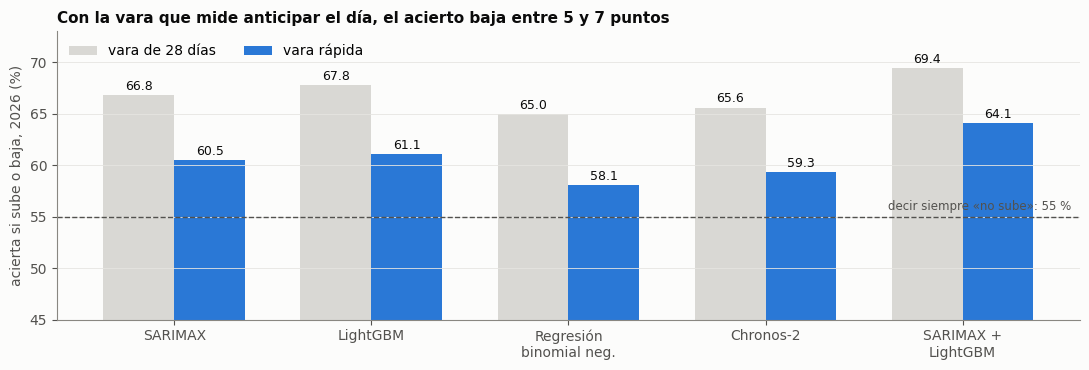

In [11]:
vara = pd.DataFrame({"vara de 28 días": [66.8, 67.8, 65.0, 65.6, 69.4], "vara rápida": [60.5, 61.1, 58.1, 59.3, 64.1]},
                    index=["SARIMAX", "LightGBM", "Regresión\nbinomial neg.", "Chronos-2", "SARIMAX +\nLightGBM"])
fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(vara)); w = .36
for k, (col, color) in enumerate([("vara de 28 días", GRIS_CLARO), ("vara rápida", AZUL)]):
    ax.bar(x + (k - .5) * w, vara[col], w, color=color, label=col)
    for xi, v in zip(x, vara[col]): ax.text(xi + (k - .5) * w, v + .5, f"{v:.1f}", ha="center", fontsize=9, color=TINTA)
ax.axhline(55, color=TINTA2, lw=1, ls="--"); ax.text(len(vara) - .45, 55.6, "decir siempre «no sube»: 55 %", ha="right", fontsize=8.5, color=TINTA2)
ax.set_xticks(x, vara.index); ax.set_ylim(45, 73); ax.set_ylabel("acierta si sube o baja, 2026 (%)"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.set_title("Con la vara que mide anticipar el día, el acierto baja entre 5 y 7 puntos", loc="left")
plt.tight_layout(); plt.show()

Las cifras de la figura salen de la comparación con 2026 y origen rodante. Con la vara de 28 días, los
individuales aciertan entre 65,0 y 67,8 % y la combinación, 69,4 %. Con la vara rápida, que es la que mide
anticipar el día, bajan a 58,1-61,1 % y a 64,1 % en la combinación. Por eso la cifra honesta es cerca del
60 % y no el 65-70 % con que había empezado. La lectura por meses lo confirma: en abril-junio, que no tuvo
escalones de Nueva EPS, SARIMAX acertó 50,2 % con una mejora de probabilidad de +0,1, es decir, nadie le
ganaba al calendario, salvo LightGBM, con 63-64 %. La cautela es que son 91 días en esos meses y la
incertidumbre es de ±5 puntos.

Comparé además los modelos con remuestreo por bloques de 7 orígenes. En la dirección de sube o baja,
ninguna diferencia entre los modelos fue significativa. Eso me obligó a corregir una frase mía: había
llamado a SARIMAX «el mejor» y lo que había era un empate; su ventaja venía de que mi criterio ponía la
probabilidad y la calibración antes que el acierto.

## La búsqueda sistemática

Quise asegurarme de que no estaba dejando una técnica buena por fuera. Hice dos cosas.

**El barrido con LazyPredict.** Ajusté de una vez 42 regresores con sus parámetros por defecto, entrenados
hasta el 31 de diciembre de 2025 y probados en 2026. La partición es temporal, y los modelos quedan
congelados, así que parten en desventaja frente a SARIMAX, que se reentrena cada 7 días. Sirve para ver qué
familias merecen afinarse, no para elegir el modelo final.

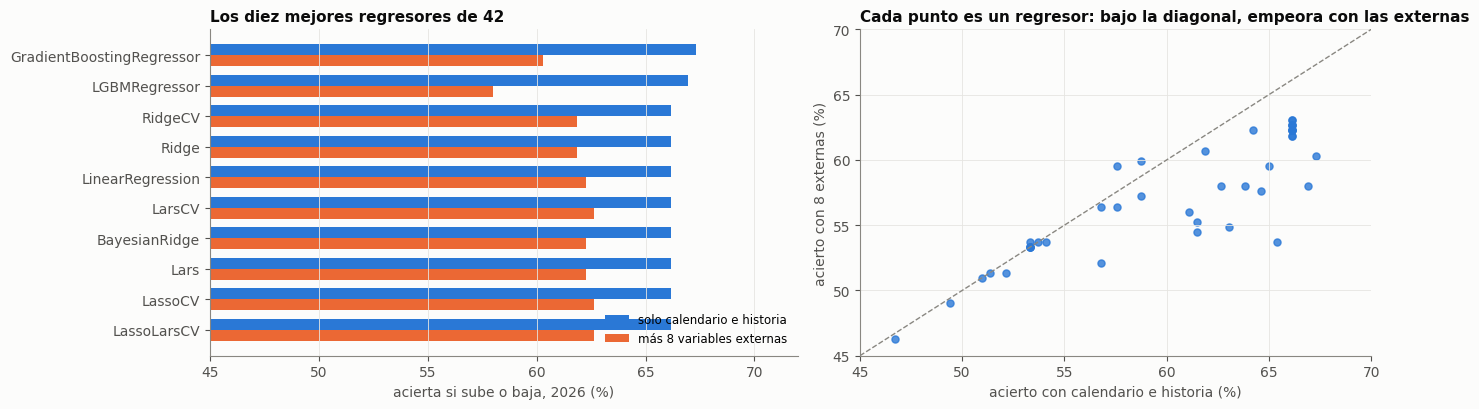

De 42 regresores, 32 acertaron menos con las 8 externas; el mejor pasó de 67.3 % a 63.0 %
mejores: {'GradientBoostingRegressor': 67.3, 'LGBMRegressor': 66.9, 'RidgeCV': 66.1, 'Ridge': 66.1}
mejores en abril-junio: {'GradientBoostingRegressor': 60.4, 'RandomForestRegressor': 60.4, 'HistGradientBoostingRegressor': 58.2}


In [12]:
L1 = pd.read_csv(RAIZ / "salidas/pronostico/lazypredict_e1.csv", index_col=0)
L3 = pd.read_csv(RAIZ / "salidas/pronostico/lazypredict_e3.csv", index_col=0)
c_ = "acierta sube/baja %"
top = L1.sort_values(c_, ascending=False).head(10)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
yy = np.arange(len(top))[::-1]
a1.barh(yy + .18, top[c_], .36, color=AZUL, label="solo calendario e historia")
a1.barh(yy - .18, L3.loc[top.index, c_], .36, color=NARANJA, label="más 8 variables externas")
a1.set_yticks(yy, top.index); a1.set_xlim(45, 72); a1.set_xlabel("acierta si sube o baja, 2026 (%)"); a1.grid(axis="y", visible=False)
a1.legend(loc="lower right", fontsize=8.5); a1.set_title("Los diez mejores regresores de 42", loc="left")
a2.scatter(L1[c_], L3.loc[L1.index, c_], s=26, color=AZUL, alpha=.8)
lim = [45, 70]; a2.plot(lim, lim, color=MUDO, lw=1, ls="--"); a2.set_xlim(lim); a2.set_ylim(lim)
a2.set_xlabel("acierto con calendario e historia (%)"); a2.set_ylabel("acierto con 8 externas (%)")
a2.set_title("Cada punto es un regresor: bajo la diagonal, empeora con las externas", loc="left")
plt.tight_layout(); plt.show()
peor = int((L3.loc[L1.index, c_] < L1[c_]).sum())
print(f"De {len(L1)} regresores, {peor} acertaron menos con las 8 externas; el mejor pasó de {L1[c_].max():.1f} % a {L3[c_].max():.1f} %")
print("mejores:", top[c_].round(1).head(4).to_dict())
print("mejores en abril-junio:", L1['acierta abr-jun %'].sort_values(ascending=False).head(3).round(1).to_dict())

La figura de la izquierda muestra los diez mejores con el calendario y la historia (azul) y los mismos con
8 variables externas (naranja). A la derecha, cada punto es un regresor: los que quedan bajo la diagonal
empeoran al agregarles las externas. Los dos primeros lugares son ensambles de árboles (GradientBoosting,
67,3 % y LightGBM, 66,9 %), y en los meses estables los árboles dan 58-60 % contra 53-54 % de los
lineales y de SARIMAX. Son implementaciones distintas que coinciden, y eso la hace candidata a señal real:
interacciones que lo lineal no ve. Con las externas, la mayoría empeora (ver la última línea de la
salida), una tercera comprobación, con una familia distinta de modelos, de que el contexto en bruto no
mejora el total. La cautela es la del cuaderno: 91 días en abril-junio dan una pista, no una prueba.

**La rejilla de hiperparámetros.** Con esa pista afiné los árboles (XGBoost, GradientBoosting y LightGBM)
con una regla fijada antes de correr: afinar con 2024, calibrar el rango con los errores fuera de muestra de
2025 y probar en 2026, sin mezclar las etapas. La rejilla real de XGBoost es esta:

configuración elegida: {'max_depth': 2, 'n_estimators': 500, 'learning_rate': 0.1} | combinaciones probadas: 12


,max_depth,n_estimators,learning_rate,mae_log,error medio en 2024 %
0,2,500,0.10,0.0975,10.2459
1,3,500,0.10,0.1021,10.7440
2,3,500,0.03,0.1025,10.7960
3,4,500,0.03,0.1035,10.9072
4,3,200,0.10,0.1037,10.9223
5,2,200,0.10,0.1039,10.9474


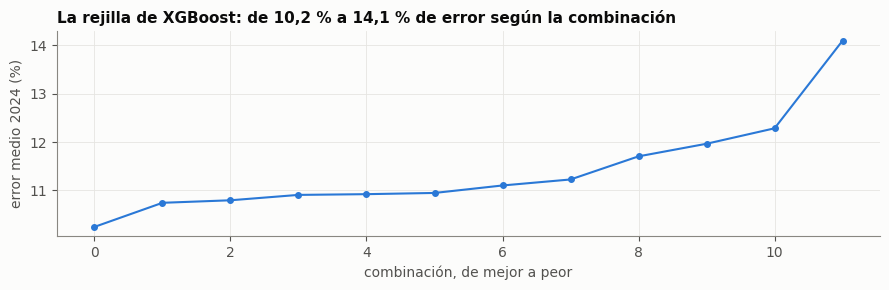

In [13]:
import json
E = json.loads((RAIZ / "salidas/pronostico/e1/_afinado_xgboost_etapas.json").read_text(encoding="utf-8"))
Rj = pd.DataFrame(E["rejilla"]).sort_values("mae_log"); Rj["error medio en 2024 %"] = (np.exp(Rj.mae_log) - 1) * 100
print("configuración elegida:", E["elegida"], "| combinaciones probadas:", len(Rj))
display(Rj.head(6).round(4))
fig, ax = plt.subplots(figsize=(9, 3)); ax.plot(range(len(Rj)), Rj["error medio en 2024 %"].values, marker="o", color=AZUL, ms=4)
ax.set_xlabel("combinación, de mejor a peor"); ax.set_ylabel("error medio 2024 (%)")
ax.set_title("La rejilla de XGBoost: de 10,2 % a 14,1 % de error según la combinación", loc="left"); plt.tight_layout(); plt.show()

La tabla y la curva muestran el error de cada combinación sobre 2024. Lo que se lee es que, entre las 12 combinaciones, el error va de
10,2 a 14,1 %, y que la rejilla eligió árboles poco profundos. El resultado más
importante es este, y no me gustó: **afinar con 2024 no mejoró a ningún árbol en 2026**, que es otro
régimen por el desplome de Nueva EPS.

| Árbol | Configuración elegida en 2024 | Acierta | BSS sube | Abril-junio | Cobertura del 80 % |
|---|---|---|---|---|---|
| LightGBM afinado | 15 hojas, 20 por hoja, 600 árboles | 66,7 % | +13,1 | 61,1 % | 76,7 % |
| XGBoost afinado | profundidad 2, 500 árboles, tasa 0,1 | 65,0 % | +11,6 | 56,8 % | 77,4 % |
| GradientBoosting afinado | profundidad 3, 500 árboles, tasa 0,1 | 64,5 % | +10,3 | 56,7 % | 76,5 % |
| **LightGBM sin afinar** | parámetros por defecto | **67,8 %** | **+15,9** | 63,3 % | 71,2 % |

Calibrar el rango con los errores de 2025 sí mejoró la cobertura (de 71 % a unos 77 %), aunque se queda
corta porque 2026 trajo choques más fuertes. Decidí conservar LightGBM sin afinar. Lo que concluyo es que la
rejilla no sustituye a tener las variables correctas, y que mi cifra de 2026 no es de prueba: comparé unos
20 diseños sobre ese mismo año, así que 2026 funcionó como validación.

## La decisión por un modelo combinado

La pregunta de si me había «casado» con SARIMAX me llevó a probar una combinación. Los dos modelos se
equivocan de forma parecida (correlación de errores de 0,85), pero no igual: el 21 % de los días uno queda
por encima de lo real y el otro por debajo, y al promediarlos el error se cancela. SARIMAX sigue el nivel y da
rangos honestos; LightGBM capta combinaciones de factores en los meses estables, pero falla más después de un
escalón de Nueva EPS. Fijé antes de calcular la regla: promedio de cuantiles con pesos iguales.

| | Acierta | BSS sube | BSS pico | Cobertura del 80 % | MAPE |
|---|---|---|---|---|---|
| Combinación, vara de 28 días | 69,4 % | +21,1 | +16,5 | 80,3 % | 8,9 % |
| Combinación, vara rápida | 64,1 % | +9,3 | — | — | — |

Frente a SARIMAX la combinación es mejor en todo, y de forma significativa en abril-junio (+7,8 puntos de
acierto, IC [+2,5; +13,6]). Frente a LightGBM, el Brier es significativamente mejor (−13,0; IC [−26,4;
−1,1]) y el acierto empata. **Decidí que la combinación SARIMAX + LightGBM fuera el modelo líder.** Después
corregí el motor: el árbol aprendía el logaritmo del conteo con el nivel como entrada y no sabe predecir un
valor que no vio, como el nivel de 2024. Con el objetivo «desvío frente al nivel» nació C0r:

| 2025 | Criterio | Acierto (28 días) | Cobertura del 80 % | MAPE |
|---|---|---|---|---|
| C0 (motor anterior) | 4,2 | 59,9 % | 78,0 % | 8,6 % |
| **C0r** (objetivo relativo) | **5,2** | **61,9 %** | **80,5 %** | **8,5 %** |

Lo adopté por la regla y no por 2026, donde empata (acierto +0,2; IC [−2,1; +3,1]). Quita el riesgo de
desplome cuando el nivel sale de lo conocido.

## Entrenar con lo que había descubierto

La auditoría me mostró algo incómodo: casi nada de lo que había descubierto en la etapa 3 había entrado al
modelo con la forma con que lo medí. Entró como indicador de volumen total y en bloque, y eso explica por
qué «el contexto no mejora el total» sin que eso pruebe que los factores no actúan. Rehice el diseño para que
cada mecanismo entrara con su subgrupo de días, su ventana, su rezago y su gatillo:

| Mecanismo | Forma en que entra |
|---|---|
| Feria | días 0 a 4 |
| Noche festiva | 7, 24 y 31 de diciembre, y el día posterior (26 de diciembre y 2 a 4 de enero) |
| Fiestas de los pueblos | a 60 km o más, más 3 días |
| Terremoto | semana 1 y semanas 2-3, medidas desde el origen |
| Paro de 2021 | como marca, no como predictor |
| Salud pública (5 familias) y red de aseguradores (6 variables) | con compuerta |
| Transiciones de clima | a 7-35 días; la compuerta del cambio brusco pasó del 77 % de los días al 29 % con el percentil 90 |
| Delitos y lesiones del Ministerio de Defensa | con 42 días de rezago de publicación |

Los coeficientes los aprende el modelo: las magnitudes que medí en los cuadernos no entran como dato. Hallé
además dos fallas de método. El árbol del motor no puede ver un episodio raro: con 30 muestras mínimas por
hoja, ninguna hoja aísla a la Feria (15 días en el entrenamiento de 2025) ni a las noches festivas (15), así
que entran también como desplazamiento lineal estimado solo con el entrenamiento. Y el Ministerio de Defensa
se usaba al origen, aunque se publica con 2 a 6 semanas de retraso: era una fuga de disponibilidad, menor
porque esos diseños perdieron.

**Cómo escogí los registros.** Elegí fechas que cubrieran eventos y calma, y fijé tres brazos antes de
calcular nada:

- M1: solo los mecanismos.
- M2: M1 más un repertorio en el que calma y eventos pesan lo mismo dentro de cada año.
- M3: M1 sin la fase fuerte de la COVID, del 15 de marzo al 31 de agosto de 2020, que son 170 días con 79
  triages por día contra 198 desde 2022.

Quitar solo la fase fuerte no se había probado: bajarle el peso a la COVID (T1) ya había empeorado los
cuatro años. La regla fue la de siempre, con 2025 en origen rodante, más la condición de no perder más de 2
puntos de mejora de probabilidad en los días de calma de 2025, un desglose obligatorio por tipo de día, y
2026 mirado una sola vez. Antes de decidir agregué un desglose descriptivo con la rejilla de 2023, 2024 y
2025, para ver si el modelo aprende cada mecanismo (no decide reemplazos).

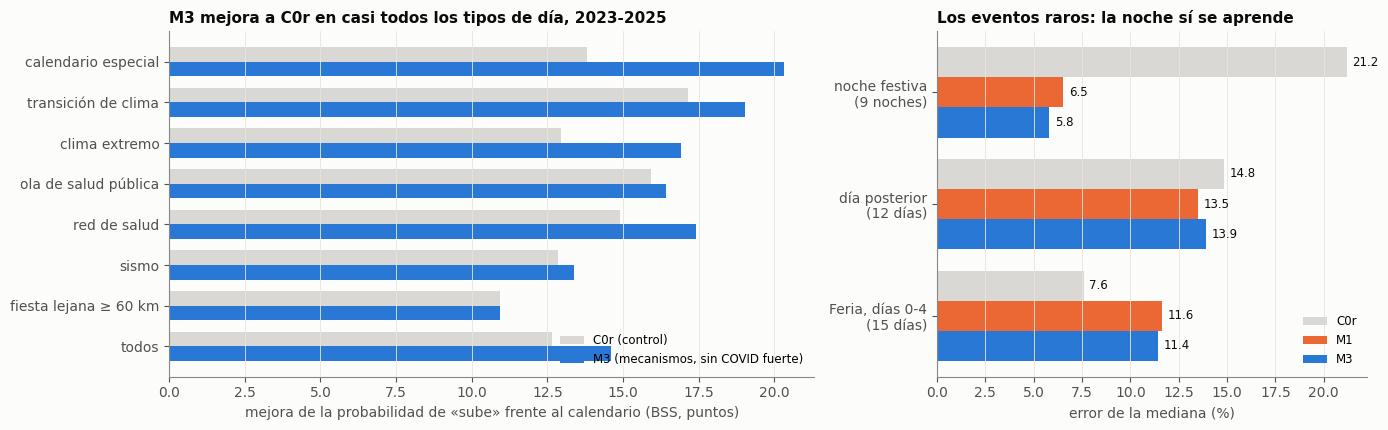

Brier M3 − C0r (x1000), todos los días 2023-2025: -4.7 (-7.7, -2.0)
error noche festiva C0r → M1 → M3: [21.19200703711337, 6.535148275538692, 5.792079059547984]
error Feria C0r → M1 → M3: [7.584392074831217, 11.629061032764795, 11.404603370481066]


In [14]:
MEC = RAIZ / "salidas/pronostico/mecanismos"
D = pd.read_csv(MEC / "_desglose_multianual.csv").set_index("tipo")
tipos = ["calendario especial", "transición de clima", "clima extremo", "ola de salud pública", "red de salud", "sismo",
         "fiesta lejana (≥ 60 km, +3 días)", "todos"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
yy = np.arange(len(tipos))[::-1]
a1.barh(yy + .18, D.loc[tipos, "C0r BSS prom"], .36, color=GRIS_CLARO, label="C0r (control)")
a1.barh(yy - .18, D.loc[tipos, "M3 BSS prom"], .36, color=AZUL, label="M3 (mecanismos, sin COVID fuerte)")
a1.set_yticks(yy, [t.replace(" (≥ 60 km, +3 días)", " ≥ 60 km") for t in tipos]); a1.set_xlabel("mejora de la probabilidad de «sube» frente al calendario (BSS, puntos)")
a1.grid(axis="y", visible=False); a1.legend(loc="lower right", fontsize=8.5)
a1.set_title("M3 mejora a C0r en casi todos los tipos de día, 2023-2025", loc="left")
ev_ = ["noche festiva", "día siguiente a noche festiva", "Feria (días 0-4)"]
yy2 = np.arange(len(ev_))[::-1]
for k, (col, color, nom) in enumerate([("C0r error %", GRIS_CLARO, "C0r"), ("M1 error %", NARANJA, "M1"), ("M3 error %", AZUL, "M3")]):
    a2.barh(yy2 + (1 - k) * .27, D.loc[ev_, col], .27, color=color, label=nom)
    for yi, v in zip(yy2 + (1 - k) * .27, D.loc[ev_, col]): a2.text(v + .3, yi, f"{v:.1f}", va="center", fontsize=8.5, color=TINTA)
a2.set_yticks(yy2, ["noche festiva\n(9 noches)", "día posterior\n(12 días)", "Feria, días 0-4\n(15 días)"]); a2.set_xlabel("error de la mediana (%)")
a2.grid(axis="y", visible=False); a2.legend(loc="lower right", fontsize=8.5); a2.set_title("Los eventos raros: la noche sí se aprende", loc="left")
plt.tight_layout(); plt.show()
print("Brier M3 − C0r (x1000), todos los días 2023-2025:", round(D.loc["todos", "M3-C0r Brier x1000"], 1), D.loc["todos", "M3-C0r IC95"])
print("error noche festiva C0r → M1 → M3:", D.loc["noche festiva", ["C0r error %", "M1 error %", "M3 error %"]].round(1).tolist())
print("error Feria C0r → M1 → M3:", D.loc["Feria (días 0-4)", ["C0r error %", "M1 error %", "M3 error %"]].round(1).tolist())

## Los resultados

**2025, el año con que se decide (origen rodante, 365 orígenes, de 1 a 7 días).**

| Modelo | Criterio | Acierto (28 días) | BSS de pico | Cobertura del 80 % | MAPE | BSS en calma |
|---|---|---|---|---|---|---|
| C0r | 5,20 | 61,9 % | 2,9 | 80,5 % | 8,48 % | −5,3 |
| M1 | 6,88 | 62,4 % | 6,3 | 80,1 % | 8,19 % | −3,5 |
| M2 | 6,45 | 63,1 % | 5,5 | 80,9 % | 8,24 % | −5,8 |
| **M3** | **6,94** | **63,2 %** | **7,9** | 78,0 % | **8,17 %** | **−1,3** |

M3 gana la regla: criterio 6,94 contra 5,20 y acierto 63,2 % contra 61,9 %, y no pierde en los días de calma
(−1,3 contra −5,3 de C0r). El Brier de M3 menos C0r es −3,39 ×1000 con la vara de 28 días [−10,0; +2,5] y
−5,16 con la rápida [−11,7; +0,5]: la mejora apunta en la dirección correcta, pero con 2025 solo no queda
firme.

**La rejilla 2023-2025 (1.088 días a un día de adelanto).** En la figura, M3 mejora a C0r en casi todos los
tipos de día. Sobre todos los días, el Brier de M3 menos C0r es −4,7 ×1000 [−7,7; −2,0], significativo, y
mejora en los tres años: 2023, de −2,5 a +0,2; 2024, de 7,1 a 9,2; 2025, de 8,5 a 10,0. Lo que más me
importa es el panel derecho: **la noche festiva se aprende**, porque el error de la mediana baja de 21,2 % con
C0r a 6,5 % con M1 en 9 noches, mientras que **la Feria no**: empeora de 7,6 % a 11,6 % con M1. Mi hipótesis
es que se suma con el desplazamiento del día posterior, entre el 2 y el 4 de enero; es una hipótesis y no la
probé. La ola de salud y las fiestas lejanas no aportan, y M1 y M2 empeoran la calma (+3,2 y +5,6 ×1000):
las variables meten ruido donde no pasa nada. M3 no.

Eso es lo que revela la comparación entre brazos: **la mayor parte de la mejora viene de quitar la COVID
fuerte y no de las variables externas**, que es lo que yo sospechaba de la COVID. En 2025 hay además muy
pocos eventos raros para juzgarlos: 5 días de Feria, 3 noches, 7 días de ola y ninguna catástrofe.

**2026, mirado una sola vez (257 orígenes).** M3 da un criterio de 15,07 contra 15,87 de C0r, y un acierto de
68,5 % contra 69,7 %. El Brier es +1,90 ×1000 [−2,9; +6,7]: es un empate. Lo calculé antes de aplicar la
regla para ganar tiempo de cómputo, pero no lo abrí hasta después de elegir. La figura muestra el
pronóstico a un día de los dos modelos contra lo real:

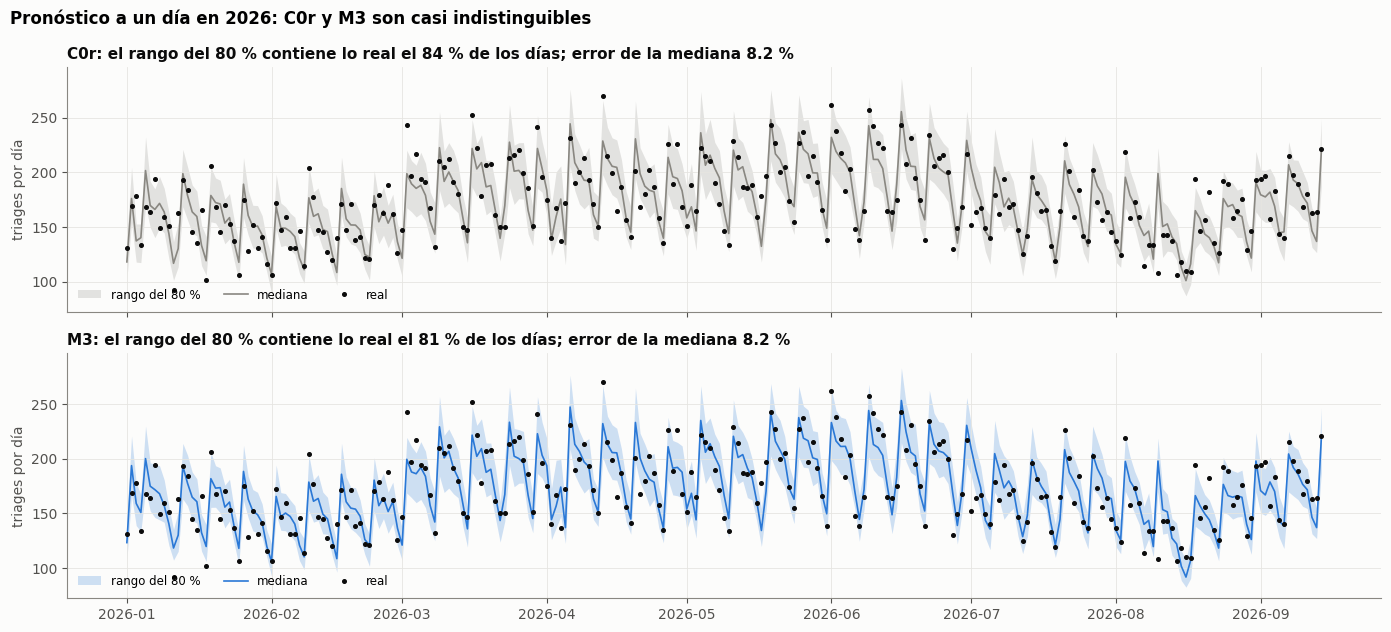

{'C0r': 'cobertura 84.0 %, error 8.2 %, 257 días', 'M3': 'cobertura 80.5 %, error 8.2 %, 257 días'}


In [15]:
Cm = pd.read_parquet(MEC / "_combos_2026.parquet"); Cm = Cm[Cm.h == 1]
fig, axes = plt.subplots(2, 1, figsize=(14, 6.4), sharex=True, sharey=True)
resum = {}
for ax, m, col in zip(axes, ["C0r", "M3"], [MUDO, AZUL]):
    s_ = Cm[Cm.modelo == m].set_index("fecha").sort_index()
    ax.fill_between(s_.index, s_.q10, s_.q90, color=col, alpha=.22, lw=0, label="rango del 80 %")
    ax.plot(s_.index, s_.q50, color=col, lw=1.2, label="mediana")
    ax.plot(s_.index, s_.real, color=TINTA, lw=0, marker="o", ms=2.6, label="real")
    cob = ((s_.real >= s_.q10) & (s_.real <= s_.q90)).mean() * 100; mape = (abs(s_.q50 - s_.real) / s_.real).mean() * 100
    resum[m] = (cob, mape, len(s_))
    ax.set_title(f"{m}: el rango del 80 % contiene lo real el {cob:.0f} % de los días; error de la mediana {mape:.1f} %", loc="left")
    ax.set_ylabel("triages por día"); ax.legend(loc="lower left", ncol=3, fontsize=8.5)
fig.suptitle("Pronóstico a un día en 2026: C0r y M3 son casi indistinguibles", x=.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
print({m: f"cobertura {c:.1f} %, error {e:.1f} %, {n} días" for m, (c, e, n) in resum.items()})

Los dos modelos siguen el nivel de 2026 de la misma forma, con el desplome de Nueva EPS en julio, y la
diferencia entre sus medianas es pequeña frente al ruido diario. Es coherente con el empate de la regla: en
2026 no hay señal de que M3 sea mejor ni peor. La cautela es que 2026 ya había servido para elegir entre
muchos diseños, así que la lectura no se apoya sobre un conjunto limpio de prueba.

**Cuántos años de historia necesita el modelo.** Entrené el motor con historia cada vez más corta (desde 2020, 2021, marzo
de 2022 y 2023) y medí cómo cambia la mejora de probabilidad en 2024 y 2025:

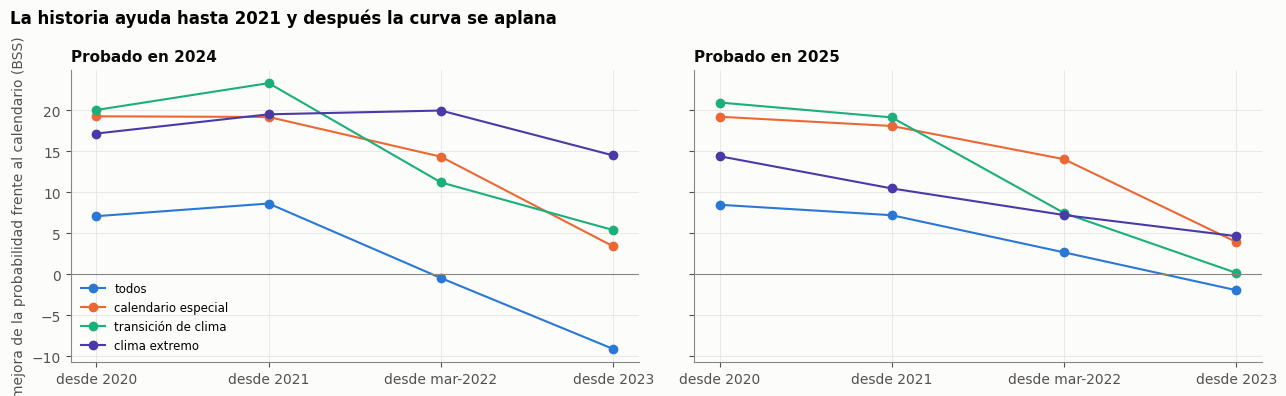

C0r, todos los días, probado en 2024: {'2020-01-01': 7.1, '2021-01-01': 8.6, '2022-03-01': -0.5, '2023-01-01': -9.1}
            tipo  episodios_entrenamiento
Feria (días 0-4)                      4.0


In [16]:
Cv = pd.read_csv(MEC / "_curvas.csv")
Cv = Cv[Cv.config == "C0r"]
orden_d = ["2020-01-01", "2021-01-01", "2022-03-01", "2023-01-01"]
sel = [("todos", AZUL), ("calendario especial", NARANJA), ("transición de clima", AQUA), ("clima extremo", VIOLETA)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, an in zip(axes, [2024, 2025]):
    for tipo, color in sel:
        z = Cv[(Cv.anio == an) & (Cv.tipo == tipo)].set_index("desde").reindex(orden_d)
        ax.plot(range(4), z.BSS.values, marker="o", color=color, label=tipo)
    ax.set_xticks(range(4), ["desde 2020", "desde 2021", "desde mar-2022", "desde 2023"]); ax.axhline(0, color=MUDO, lw=.8)
    ax.set_title(f"Probado en {an}", loc="left")
axes[0].set_ylabel("mejora de la probabilidad frente al calendario (BSS)"); axes[0].legend(fontsize=8.5, loc="lower left")
fig.suptitle("La historia ayuda hasta 2021 y después la curva se aplana", x=.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
z24 = Cv[(Cv.anio == 2024) & (Cv.tipo == "todos")].set_index("desde").BSS.reindex(orden_d).round(1)
print("C0r, todos los días, probado en 2024:", z24.to_dict())
raros = Cv[(Cv.anio == 2025) & (Cv.desde == "2020-01-01") & Cv.tipo.isin(["Feria (días 0-4)", "El Niño / La Niña fuerte"])][["tipo", "episodios_entrenamiento"]]
print(raros.to_string(index=False))

La figura muestra, para cuatro tipos de día, la mejora que se obtiene según desde cuándo se entrena. Para
2024, con todos los días, la mejora es de −9,1 si se entrena desde 2023, −0,5 desde marzo de 2022, 8,6
desde 2021 y 7,1 desde 2020: la historia ayuda mucho hasta 2021 y después se aplana. Esa es la lectura
que fijé antes de mirar (casi todos los tipos salen «indeterminados», y la calma de C0r y todos los días de
M1 sin la COVID salen «aplanados»). Para los días comunes los registros históricos alcanzan. Para los eventos
raros la muestra es insuficiente, y la base no tiene triage anterior a 2020: en el entrenamiento hay 4 Ferias, 1
episodio de El Niño o La Niña fuerte, ninguna catástrofe y 1 ola del régimen actual. Eso no se arregla con
más modelo; se arreglaría con los años, o con registros de otros hospitales o del CRUE.

# Decisiones y conclusiones de la predicción

**Decidí que M3 sea el modelo principal** para adelantos de 1 a 7 días. Es el mismo criterio con que C0r
reemplazó a C0: se elige con 2025 y 2026, que empató, no revierte. Esto supera lo que dije antes, que el modelo
principal era el control corregido. M3 es el motor corregido, con los mecanismos en la forma en que los medí y
sin la fase fuerte de la COVID.

**Decidí llevar M3 a la predicción semanal**, que es el formato que más se va a usar. La respuesta semanal
estaba construida con C0r porque las variables de clima de M3 exigen adelantos de 7 días o menos, y la
semana usa 21 días. La decisión es pasarlo con una variante de M3 preregistrada para ese horizonte, y la
predicción se guarda una sola vez y se versiona antes de conocer lo real.

Lo que me llevo de esta parte:

- La mejora real de M3 es modesta (acierto de 63,2 % contra 61,9 % en 2025) y viene sobre todo de quitar la
  COVID fuerte, no de las variables externas.
- Lo que sí se aprende bien con las variables es la noche festiva (error de 21,2 % a 6,5 %); la Feria no.
- Con las probabilidades altas hay que ser cauteloso: un «70 % o más» vale lo que un 65 % real.

Los límites son estos. En 2025 no hay eventos raros suficientes para juzgar los mecanismos raros, y en 2026
el resultado es un empate. Las formas de la Feria, de las noches y del corte de 60 km se midieron con datos
que incluyen 2025, y la del terremoto, con 2026, de modo que esos años no son totalmente ajenos al diseño. La
lluvia de la NASA de agosto de 2026 es provisional. Y 2026 sirvió para elegir entre unos 20 diseños, así que
las cifras de ese año son de validación y no de prueba. Los mecanismos sin muestra (Feria, El Niño, catástrofes)
son los que más se beneficiarán de tener más años de registro.